# nLightG2 — passive2 only

Single-plane corridor2 recording, ~30.035 Hz. Existing Suite2p registration is reused by default. All outputs belong to `results/passive2/suite2p`.

The behavioral analyses use `aligned_data` from this recording’s `all_data.pkl`, including its Stim, Reward and pupil columns. The raw `data.pkl` has two extra rows and is not used. Event labels retain the confirmed mapping Stim 2 = Grating 1, Stim 4 = Grating 2.

Start with the setup cells, then run extraction, plots, and analyses as needed. Full lag-significance tests may take longer at this frame rate. Video durations in seconds depend on the frame rate.


In [1]:
# Shared nLightG2 plot typography.
import matplotlib as mpl
mpl.rcParams["font.family"] = "sans-serif"
mpl.rcParams["font.sans-serif"] = ["Helvetica Neue", "Helvetica", "Arial"]
mpl.rcParams["xtick.labelsize"] = 12
mpl.rcParams["ytick.labelsize"] = 12
mpl.rcParams["axes.labelsize"] = 12
mpl.rcParams["axes.titlesize"] = 14

from pathlib import Path
import json
import re
import numpy as np
import matplotlib.pyplot as plt
import tifffile

INPUT_DIR = Path('/Volumes/mrsic_flogel/public/projects/SaEl_20220201_VIP/2pdata/LC/grab/meg1/corridor2/raw_data')
INPUT_TIFFS = [INPUT_DIR / f'file_00002_{part:05d}.tif' for part in (1, 2, 3, 4)]
INPUT_TIFF = INPUT_TIFFS[0]
OUTPUT_BASE_DIR = Path('/Users/megyoung/mini2p-preprocessing/results/passive2')  # local derivatives
N_PLANES = 1  # None: detect 1 or 4 from metadata; otherwise set explicitly to 1 or 4
N_CHANNELS = 1
FS_HZ_OVERRIDE = None  # verified Hz PER PLANE, only if metadata is unavailable/incorrect
SUITE2P_SAVE_FOLDER = 'suite2p'

OVERWRITE_PREPARED_TIFF = False
PREPARE_CHUNK_VOLUMES = 100
TILE_EXCLUDE_BELOW_PERCENTILE = 0  # per-plane mean raw fluorescence; 0 disables
NIMG_INIT = 1000
REGISTRATION_BATCH_SIZE = 500
BAD_FRAME_THRESHOLD = 0.7
TILE_SIZE_PX = 32
TILE_BATCH_FRAMES = 500
BASELINE_WINDOW_S = 60
BASELINE_PERCENTILE = 50
TILE_QC_ID = 0

if INPUT_TIFF is None:
    raise ValueError('Set INPUT_TIFF to the Big2P acquisition TIFF, then rerun.')
INPUT_TIFF = Path(INPUT_TIFF)
for input_part in INPUT_TIFFS:
    if not input_part.is_file():
        raise FileNotFoundError(input_part)
OUTPUT_DIR = INPUT_TIFF.parent if OUTPUT_BASE_DIR is None else Path(OUTPUT_BASE_DIR)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
REGISTRATION_ROOT = OUTPUT_DIR / SUITE2P_SAVE_FOLDER
PREPARED_INPUT_DIR = REGISTRATION_ROOT / 'input'
PREPARED_INPUT_DIR.mkdir(parents=True, exist_ok=True)

# Passive2-only behavior source and reuse policy.
import sys
import pandas as pd
HELPER_DIR = Path('/Users/megyoung/mini2p-preprocessing/scripts')
sys.path.insert(0, str(HELPER_DIR))
REUSE_EXISTING_REGISTRATION = True
ALL_DATA_PATH = INPUT_DIR / 'suite2p' / 'all_data.pkl'
ALIGNED_TABLE_PATH = REGISTRATION_ROOT / 'passive2_aligned_data.pkl'
if not ALL_DATA_PATH.exists():
    raise FileNotFoundError(ALL_DATA_PATH)
behavior_bundle = pd.read_pickle(ALL_DATA_PATH)
aligned_table = behavior_bundle['aligned_data']
required_columns = {'Time', 'Stim', 'Reward', 'pupil_diameter', 'Speed_Absolute'}
if not isinstance(aligned_table, pd.DataFrame) or not required_columns.issubset(aligned_table.columns):
    raise ValueError('all_data.pkl aligned_data lacks required behavior columns')
ops_path = REGISTRATION_ROOT / 'plane0' / 'ops.npy'
if REUSE_EXISTING_REGISTRATION:
    existing_ops = np.load(ops_path, allow_pickle=True).item()
    if len(aligned_table) != int(existing_ops['nframes']):
        raise ValueError('aligned_data row count does not match registered movie')
    if list(sorted(p.name for p in REGISTRATION_ROOT.glob('plane[0-9]*') if (p/'ops.npy').exists())) != ['plane0']:
        raise ValueError('Expected only plane0 for passive2')
aligned_table.to_pickle(ALIGNED_TABLE_PATH)
print('Behavior source:', ALL_DATA_PATH, '—', len(aligned_table), 'aligned samples')


Behavior source: /Volumes/mrsic_flogel/public/projects/SaEl_20220201_VIP/2pdata/LC/grab/meg1/corridor2/raw_data/suite2p/all_data.pkl — 16898 aligned samples


In [2]:
if REUSE_EXISTING_REGISTRATION:
    FS_HZ = float(existing_ops['fs'])
    N_PLANES = 1
    rate_source = 'existing Suite2p ops.npy'
    if not np.isfinite(FS_HZ) or FS_HZ <= 0:
        raise ValueError('Invalid saved sampling rate')
    print(f'Using registered plane0: {FS_HZ:.6g} Hz, {existing_ops["nframes"]} frames')
else:
    def metadata_number(text, key):
        match = re.search(r'(?:^|\n)\s*' + re.escape(key) + r'\s*=\s*([+\-0-9.eE]+)', text)
        return float(match.group(1)) if match else None
    
    
    def resolve_plane_count(configured, frame_data, header_text):
        """Resolve one- versus four-plane acquisition without guessing from filenames."""
        if configured is not None:
            configured = int(configured)
            if configured not in (1, 4):
                raise ValueError('N_PLANES must be None, 1, or 4')
        candidates = []
        for key in ('SI.hStackManager.numSlices',
                    'SI.hStackManager.numFramesPerVolumeWithFlyback'):
            value = frame_data.get(key)
            if value is None:
                value = metadata_number(header_text, key)
            if value is not None:
                candidates.append((key, int(value)))
        supported = [(key, value) for key, value in candidates if value in (1, 4)]
        detected_values = {value for _, value in supported}
        if len(detected_values) > 1:
            raise ValueError(f'Conflicting plane-count metadata: {supported}')
        detected = next(iter(detected_values)) if detected_values else None
        if configured is None:
            if detected is None:
                raise ValueError('Could not detect 1 or 4 planes; set N_PLANES explicitly after verifying the acquisition')
            return detected, 'ScanImage metadata'
        if detected is not None and detected != configured:
            raise ValueError(f'N_PLANES={configured}, but metadata report {detected}')
        return configured, 'explicit configuration'
    
    
    # Read the first part once, resolve the plane count, then validate every part.
    with tifffile.TiffFile(INPUT_TIFF) as tif:
        metadata = tif.scanimage_metadata or {}
        frame_data = metadata.get('FrameData', {})
        header = '\n'.join(f'{key} = {value}' for key, value in frame_data.items())
        header += '\n' + (tif.pages[0].description or '')
        n_pages = len(tif.pages)
        frame_shape = tif.pages[0].shape
        N_PLANES, plane_count_source = resolve_plane_count(N_PLANES, frame_data, header)
        timestamps = []
        for index in range(0, min(n_pages, N_PLANES * 200), N_PLANES):
            stamp = metadata_number(tif.pages[index].description or '', 'frameTimestamps_sec')
            if stamp is not None:
                timestamps.append(stamp)
    
    expected_rate = frame_data.get('SI.hRoiManager.scanVolumeRate')
    for part in INPUT_TIFFS:
        with tifffile.TiffFile(part) as part_tif:
            part_meta = (part_tif.scanimage_metadata or {}).get('FrameData', {})
            slots = part_meta.get('SI.hStackManager.numFramesPerVolumeWithFlyback')
            if slots is not None and int(slots) != N_PLANES:
                raise ValueError(f'Unexpected plane/flyback layout in {part}: {slots} frames per volume')
            slices = part_meta.get('SI.hStackManager.numSlices')
            if slices is not None and int(slices) != N_PLANES:
                raise ValueError(f'Unexpected slice count in {part}: {slices}')
            channels = part_meta.get('SI.hChannels.channelSave')
            if channels is not None and np.asarray(channels).size != N_CHANNELS:
                raise ValueError(f'Unexpected saved-channel count in {part}')
            actual_rate = part_meta.get('SI.hRoiManager.scanVolumeRate')
            if expected_rate is not None and actual_rate is not None and not np.isclose(expected_rate, actual_rate):
                raise ValueError(f'Volume rate changes in {part}')
    
    print('Relevant acquisition metadata:')
    for line in header.splitlines():
        if any(key in line for key in ['scanFrameRate', 'scanVolumeRate', 'numSlices',
                                       'numFramesPerVolumeWithFlyback', 'channelSave',
                                       'numDiscardFlybackFrames', 'zs =']):
            print(line)
    if len(frame_shape) != 2:
        raise ValueError('Expected 2D TIFF pages')
    channel_match = re.search(r'(?:^|\n)\s*SI.hChannels.channelSave\s*=([^\n]+)', header)
    if channel_match and len(re.findall(r'\d+', channel_match.group(1))) != N_CHANNELS:
        raise ValueError('Saved channel count differs from single-channel configuration')
    volume_rate = metadata_number(header, 'SI.hRoiManager.scanVolumeRate')
    intervals = np.diff(timestamps)
    timestamp_rate = (1 / np.median(intervals)
                      if len(intervals) >= 3 and np.all(intervals > 0) else None)
    print(f'Plane count: {N_PLANES} ({plane_count_source})')
    print('Header volume rate:', volume_rate, 'Hz; timestamp estimate:', timestamp_rate, 'Hz')
    if FS_HZ_OVERRIDE is not None:
        FS_HZ, rate_source = float(FS_HZ_OVERRIDE), 'manual override'
    elif volume_rate is not None and volume_rate > 0:
        FS_HZ, rate_source = volume_rate, 'ScanImage scanVolumeRate'
    elif timestamp_rate is not None:
        FS_HZ, rate_source = timestamp_rate, 'same-plane TIFF timestamps'
    else:
        raise ValueError('Cannot determine per-plane rate. Set a verified FS_HZ_OVERRIDE.')
    if not np.isfinite(FS_HZ) or FS_HZ <= 0:
        raise ValueError('Per-plane rate must be positive and finite')
    if FS_HZ_OVERRIDE is None and timestamp_rate is not None and abs(timestamp_rate/FS_HZ-1) > 0.05:
        raise ValueError('Header and timestamp rates disagree by >5%; inspect the acquisition layout')
    print(f'First file: {n_pages} pages; {FS_HZ:.6g} Hz/plane ({rate_source})')
    print(f'Confirmed cyclic layout with {N_PLANES} plane(s) and no saved flyback pages.')


Using registered plane0: 30.0351 Hz, 16898 frames


## Consolidate TIFF parts into complete volumes

This step preserves pixel intensities and performs no scan-line correction. It carries plane cycles across TIFF splits and drops only the last incomplete volume (at most three pages). The prepared TIFF and its page-count metadata are saved under the Suite2p root’s `input` folder. Output is promoted from a temporary file only when the complete write succeeds.


In [3]:
if REUSE_EXISTING_REGISTRATION:
    print('Reusing passive2 registration; this preparation/registration step is skipped.')
else:
    def iter_complete_plane_blocks(input_paths, n_planes, chunk_volumes, summary):
        """Carry cycles across TIFF splits; omit only a final incomplete volume."""
        if n_planes < 1 or chunk_volumes < 1:
            raise ValueError('Plane count and chunk size must be positive')
        pending = []
        total_pages = 0
        next_frame_number = None
        shape = None
        for input_path in input_paths:
            file_pages = 0
            with tifffile.TiffFile(input_path) as tif:
                for page in tif.pages:
                    # Detect dropped/reordered pages when ScanImage numbering is present.
                    number = metadata_number(page.description or '', 'frameNumberAcquisition')
                    if number is not None:
                        number = int(number)
                        if total_pages == 0 and (number - 1) % n_planes:
                            raise ValueError('Recording does not start at plane 0')
                        if next_frame_number is not None and number != next_frame_number:
                            raise ValueError(f'Nonconsecutive frame number in {input_path}: '
                                             f'expected {next_frame_number}, found {number}')
                        next_frame_number = number + 1
                    else:
                        next_frame_number = None
                    frame = page.asarray()
                    if shape is None:
                        shape = frame.shape
                    if frame.shape != shape:
                        raise ValueError(f'Frame dimensions change in {input_path}')
                    pending.append(frame)
                    total_pages += 1
                    file_pages += 1
                    if len(pending) == n_planes * chunk_volumes:
                        yield np.stack(pending)
                        pending = []
            summary['files'].append({'path': str(input_path), 'pages': file_pages})
        complete = len(pending) // n_planes * n_planes
        if complete:
            yield np.stack(pending[:complete])
        summary.update(input_pages=total_pages, output_pages=total_pages-(len(pending)-complete),
                       omitted_final_pages=len(pending)-complete)
        if total_pages < n_planes:
            raise ValueError('Recording contains no complete plane cycle')
    
    
    PREPARED_TIFF = PREPARED_INPUT_DIR / f'{INPUT_TIFF.stem}_complete_volumes.tif'
    if PREPARED_TIFF.exists() and not OVERWRITE_PREPARED_TIFF:
        raise FileExistsError(f'{PREPARED_TIFF} exists; set OVERWRITE_PREPARED_TIFF=True to replace it')
    partial_tiff = PREPARED_TIFF.with_name(PREPARED_TIFF.stem + '.partial.tif')
    cycle_summary = {'files': [], 'policy': 'carry across files; omit final incomplete volume only'}
    with tifffile.TiffWriter(partial_tiff, bigtiff=True) as writer:
        for block in iter_complete_plane_blocks(INPUT_TIFFS, N_PLANES, PREPARE_CHUNK_VOLUMES, cycle_summary):
            for frame in block:
                writer.write(frame, photometric='minisblack', metadata=None)
    partial_tiff.replace(PREPARED_TIFF)
    PREPARED_TIFF.with_suffix('.json').write_text(json.dumps(cycle_summary, indent=2))
    print(f"Prepared {cycle_summary['output_pages']} unchanged intensity pages; "
          f"omitted {cycle_summary['omitted_final_pages']} pages from the final incomplete volume.")
    SUITE2P_INPUT_TIFFS = [PREPARED_TIFF]


Reusing passive2 registration; this preparation/registration step is skipped.


## Two-pass rigid registration

Suite2p demultiplexes `N_PLANES` and registers each plane independently. With one plane it writes only `plane0`; with four planes it writes `plane0` through `plane3`. The raw binary is retained for the second pass. Reference initialization selects correlated frames; this is not an explicit stationary-frame classification. Use a fresh output folder to prevent accidental reuse of a registration made with a different plane count.


In [ ]:
if REUSE_EXISTING_REGISTRATION:
    print('Reusing passive2 registration; this preparation/registration step is skipped.')
else:
    from suite2p import default_settings
    from suite2p.run_s2p import run_s2p
    
    settings = default_settings()
    settings['fs'] = FS_HZ
    settings['registration'].update({
        'align_by_chan2': False, 'do_bidiphase': False, 'bidiphase': 0,
        'nonrigid': False, 'norm_frames': False, 'nimg_init': NIMG_INIT,
        'th_badframes': BAD_FRAME_THRESHOLD, 'two_step_registration': True,
        'batch_size': REGISTRATION_BATCH_SIZE,
    })
    settings['run'].update({'do_registration': 1, 'do_detection': False, 'do_deconvolution': False})
    settings['io']['save_mat'] = False
    registration_dir = OUTPUT_DIR / SUITE2P_SAVE_FOLDER
    if any(registration_dir.glob('plane*/ops.npy')) or any(registration_dir.glob('plane*/data.bin')):
        raise FileExistsError('Registration folder is not empty. Select a new SUITE2P_SAVE_FOLDER or skip this cell to analyze existing output.')
    db = {'data_path': [str(SUITE2P_INPUT_TIFFS[0].parent)],
          'file_list': [p.name for p in SUITE2P_INPUT_TIFFS], 'look_one_level_down': False,
          'save_path0': str(OUTPUT_DIR), 'save_folder': SUITE2P_SAVE_FOLDER,
          'nplanes': N_PLANES, 'nchannels': N_CHANNELS, 'functional_chan': 1,
          'keep_movie_raw': True}
    suite2p_db_paths = run_s2p(settings=settings, db=db)
    ( registration_dir / 'acquisition_settings.json').write_text(json.dumps({
        'input_tiffs': [str(p) for p in INPUT_TIFFS], 'registration_inputs': [str(p) for p in SUITE2P_INPUT_TIFFS],
        'nplanes': N_PLANES, 'fs_hz_per_plane': FS_HZ, 'rate_source': rate_source,
        'bidiphase_applied': False}, indent=2))


Reusing passive2 registration; this preparation/registration step is skipped.


## Tile traces, brightness exclusion, and consolidated exports

`TILE_EXCLUDE_BELOW_PERCENTILE=10` excludes tiles below the 10th percentile of their time-mean raw fluorescence, calculated separately per plane over non-bad frames. This is fluorescence intensity, not absolute ΔF/F₀ or the absolute value of signed pixel values. Set 0 to disable. Ties at the cutoff are retained, so the excluded fraction may differ slightly from 10%. Brightness is a screening rule, not proof that a tile is noise.

Each `planeN` folder contains Suite2p’s `ops.npy` and registered binaries plus `F.npy`, `F0.npy`, and `dff.npy` (retained tiles × frames). `dff` is fractional, not percent. `tile_ids.npy` and `tile_bounds_yxyx.npy` map rows back to the original grid. `tile_selection.npz` preserves brightness and exclusion decisions for all tiles. The compressed trace export remains available for plotting. No Fneu or neuropil subtraction is used. Baseline defaults remain a 60-second centered rolling 20th percentile; bad frames are excluded from estimation and marked NaN in dff. Re-running replaces derivative traces.


plane0: retained 210/210 tiles; brightness cutoff 1453


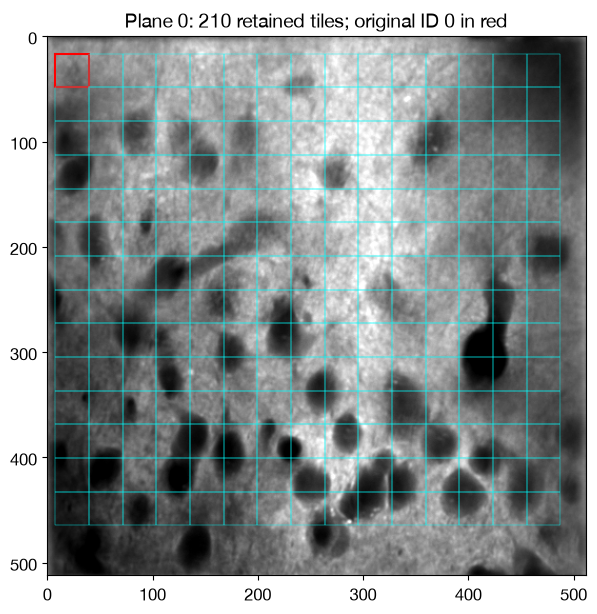

In [4]:
# Extract and save directly in each Suite2p plane folder.
import runpy
extract_helpers = runpy.run_path(str(Path('/Users/megyoung/mini2p-preprocessing/scripts/extract_big2p_tiles.py')))
extract_plane_tiles = extract_helpers['extract_plane_tiles']
label_tile_axis = extract_helpers['label_tile_axis']
expected_plane_names = {f'plane{plane}' for plane in range(N_PLANES)}
existing_plane_names = {folder.name for folder in (OUTPUT_DIR / SUITE2P_SAVE_FOLDER).glob('plane[0-9]*')
                        if (folder / 'ops.npy').exists()}
if existing_plane_names != expected_plane_names:
    raise ValueError(f'Processed plane folders {sorted(existing_plane_names)} do not match '
                     f'N_PLANES={N_PLANES} ({sorted(expected_plane_names)}). Use the correct output folder.')
tile_output_paths = []
for plane in range(N_PLANES):
    plane_dir = OUTPUT_DIR / SUITE2P_SAVE_FOLDER / f'plane{plane}'
    output = extract_plane_tiles(plane_dir, FS_HZ, TILE_SIZE_PX, TILE_BATCH_FRAMES,
        TILE_EXCLUDE_BELOW_PERCENTILE, BASELINE_WINDOW_S, BASELINE_PERCENTILE)
    tile_output_paths.append(output)
    ops = np.load(plane_dir / 'ops.npy', allow_pickle=True).item()
    with np.load(output) as saved:
        tile_ids, bounds = saved['tile_ids'], saved['tile_bounds_yxyx']
        times, F, F0, dff = saved['time_s'], saved['F'], saved['F0'], saved['dff']
    from matplotlib.patches import Rectangle
    fig, ax = plt.subplots(figsize=(8, 7))
    mean = np.asarray(ops['meanImg'])
    low, high = np.nanpercentile(mean, [1, 99.8])
    ax.imshow(mean, cmap='gray', vmin=low, vmax=high)
    matches = np.flatnonzero(tile_ids == TILE_QC_ID)
    row = int(matches[0]) if len(matches) else 0
    if not len(matches):
        print(f'QC tile {TILE_QC_ID} excluded; showing original tile ID {tile_ids[row]}')
    for i, (ya, yb, xa, xb) in enumerate(bounds):
        ax.add_patch(Rectangle((xa-.5, ya-.5), xb-xa, yb-ya, fill=False,
            edgecolor='red' if i==row else 'cyan', linewidth=1.5 if i==row else .3))
    ax.set_title(f'Plane {plane}: {len(tile_ids)} retained tiles; original ID {tile_ids[row]} in red')
    fig.savefig(plane_dir / 'tile_grid.png', dpi=150)
    plt.show(); plt.close(fig)


## All-tile ΔF/F₀ heatmaps by plane

Time is on the x-axis; tile IDs are on the y-axis in the original row-by-row grid order. All planes share a color scale starting at 0% (purple); negative values also appear purple; by default its limit is the pooled 99th percentile of absolute ΔF/F₀. Color saturation affects display only. Gray represents missing/bad frames. No temporal smoothing or tile sorting is applied.

Only retained tiles are loaded from the filtered trace export: excluded tiles are absent, not represented as zero-valued or blank rows. Y-axis labels retain original grid IDs, so IDs can skip numbers.


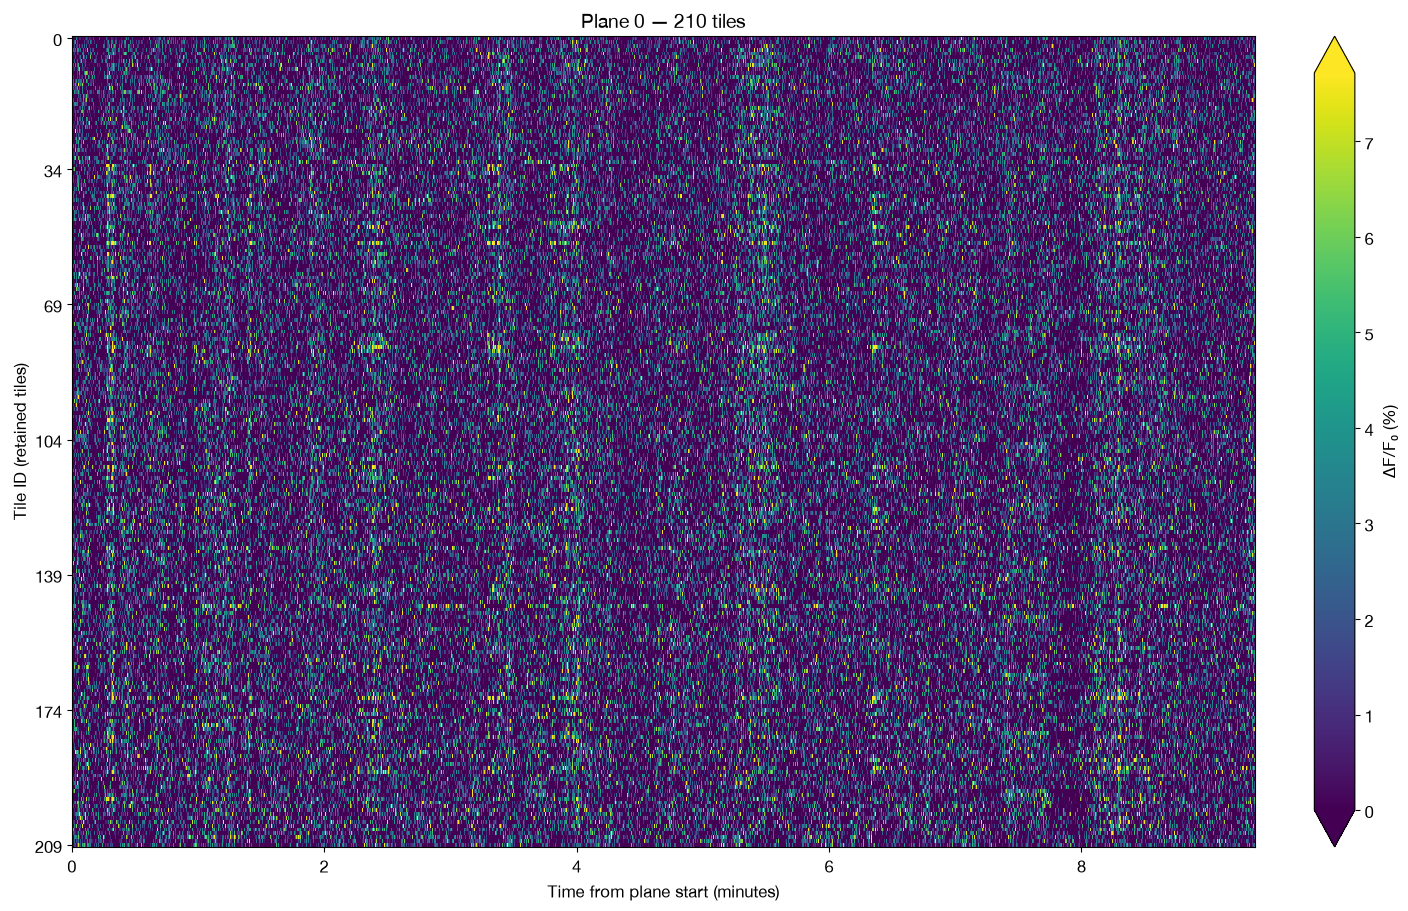

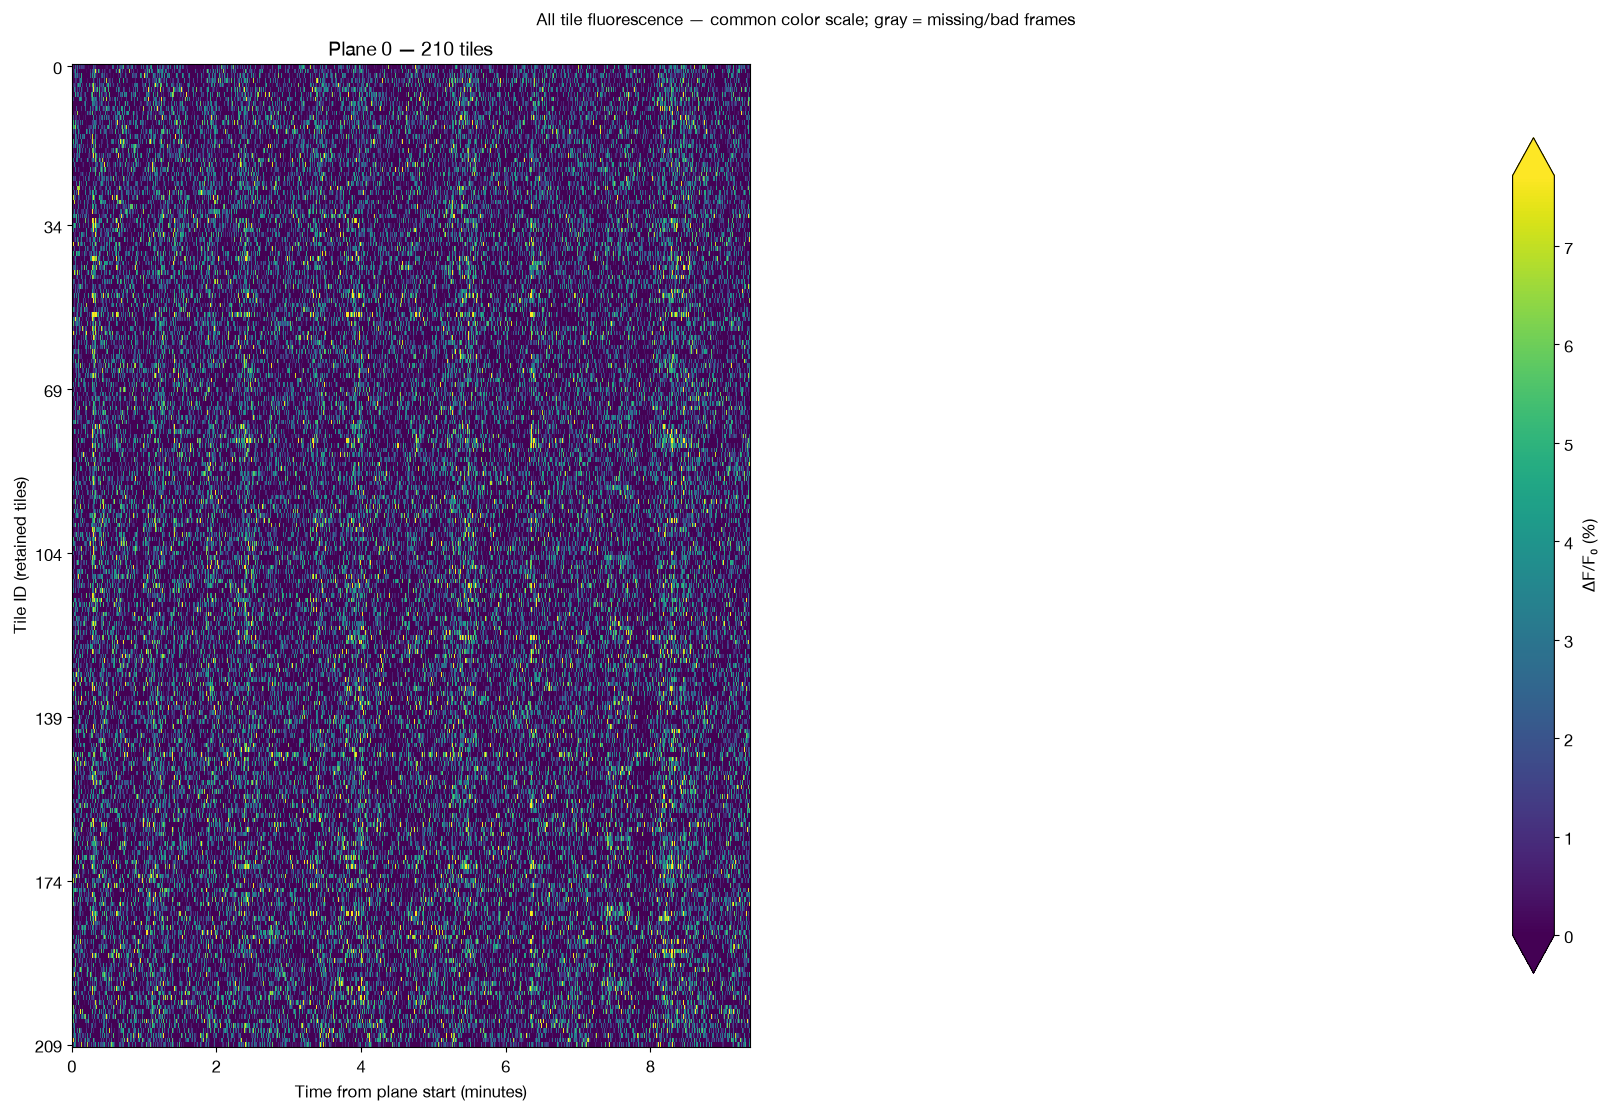

Common color limits: 0.00% to 7.72% (values outside limits saturate; saved traces unchanged)
Saved overview: /Users/megyoung/mini2p-preprocessing/results/passive2/suite2p/all_planes_tile_dff_heatmaps.png


In [5]:
# All tiles, in their original spatial-grid order; no sorting or smoothing.
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

HEATMAP_MIN_PERCENT = 0.0  # zero and negative values appear purple
HEATMAP_LIMIT_PERCENT = None  # None: common 99th percentile of absolute ΔF/F₀ (%)
HEATMAP_ABS_PERCENTILE = 99
heatmap_data = []
for plane in range(N_PLANES):
    plane_dir = OUTPUT_DIR / SUITE2P_SAVE_FOLDER / f'plane{plane}'
    with np.load(plane_dir / 'tile_fluorescence_dff.npz') as saved:
        values = saved['dff'] * 100
        minutes = saved['time_s'] / 60
    if values.ndim != 2 or values.shape[1] != len(minutes) or len(minutes) < 2:
        raise ValueError(f'Invalid heatmap dimensions in {plane_dir}')
    heatmap_data.append((plane, plane_dir, values, minutes))
finite_values = np.concatenate([np.abs(values[np.isfinite(values)])
                               for _, _, values, _ in heatmap_data])
if not len(finite_values):
    raise ValueError('No finite ΔF/F₀ values to plot')
limit = (float(np.percentile(finite_values, HEATMAP_ABS_PERCENTILE))
         if HEATMAP_LIMIT_PERCENT is None else float(HEATMAP_LIMIT_PERCENT))
del finite_values
if not np.isfinite(limit) or limit <= 0:
    raise ValueError('Heatmap color limit must be positive and finite')
cmap = plt.get_cmap('viridis').copy()
cmap.set_bad('lightgray')

def draw_tile_heatmap(ax, plane, values, minutes):
    dt = np.median(np.diff(minutes))
    image = ax.imshow(np.ma.masked_invalid(values), aspect='auto', origin='upper',
                      interpolation='nearest', cmap=cmap, vmin=HEATMAP_MIN_PERCENT, vmax=limit,
                      extent=[minutes[0]-dt/2, minutes[-1]+dt/2,
                              len(values)-0.5, -0.5])
    ax.set_title(f'Plane {plane} — {len(values)} tiles')
    ax.set_xlabel('Time from plane start (minutes)')
    label_tile_axis(ax, OUTPUT_DIR / SUITE2P_SAVE_FOLDER / f'plane{plane}')
    return image

heatmap_paths = []
for plane, plane_dir, values, minutes in heatmap_data:
    fig, ax = plt.subplots(figsize=(14, 9), constrained_layout=True)
    im = draw_tile_heatmap(ax, plane, values, minutes)
    fig.colorbar(im, ax=ax, label='ΔF/F₀ (%)', extend='both')
    path = plane_dir / 'all_tile_dff_heatmap.png'
    fig.savefig(path, dpi=180)
    heatmap_paths.append(path)
    plt.show()
    plt.close(fig)

fig, axes = plt.subplots(int(np.ceil(N_PLANES/2)), 2, figsize=(16, 11),
                         constrained_layout=True, squeeze=False)
for ax, (plane, plane_dir, values, minutes) in zip(axes.flat, heatmap_data):
    im = draw_tile_heatmap(ax, plane, values, minutes)
for ax in list(axes.flat)[N_PLANES:]:
    ax.set_visible(False)
fig.colorbar(im, ax=list(axes.flat), label='ΔF/F₀ (%)', extend='both', shrink=0.85)
fig.suptitle('All tile fluorescence — common color scale; gray = missing/bad frames')
heatmap_overview_path = OUTPUT_DIR / SUITE2P_SAVE_FOLDER / 'all_planes_tile_dff_heatmaps.png'
fig.savefig(heatmap_overview_path, dpi=180)
plt.show()
plt.close(fig)
print(f'Common color limits: {HEATMAP_MIN_PERCENT:.2f}% to {limit:.2f}% (values outside limits saturate; saved traces unchanged)')
print('Saved overview:', heatmap_overview_path)


## Whole-image ROI comparison

Each plane uses one ROI covering its entire valid registered crop, excluding registration borders and including pixels discarded by incomplete edge tiles. Fluorescence is averaged across pixels before computing a separate rolling baseline and ΔF/F₀, using the saved tile baseline settings and bad-frame mask. This differs from averaging already-normalized tile ΔF/F₀ traces. The comparison pairs each viridis tile heatmap with the whole-image ROI trace.


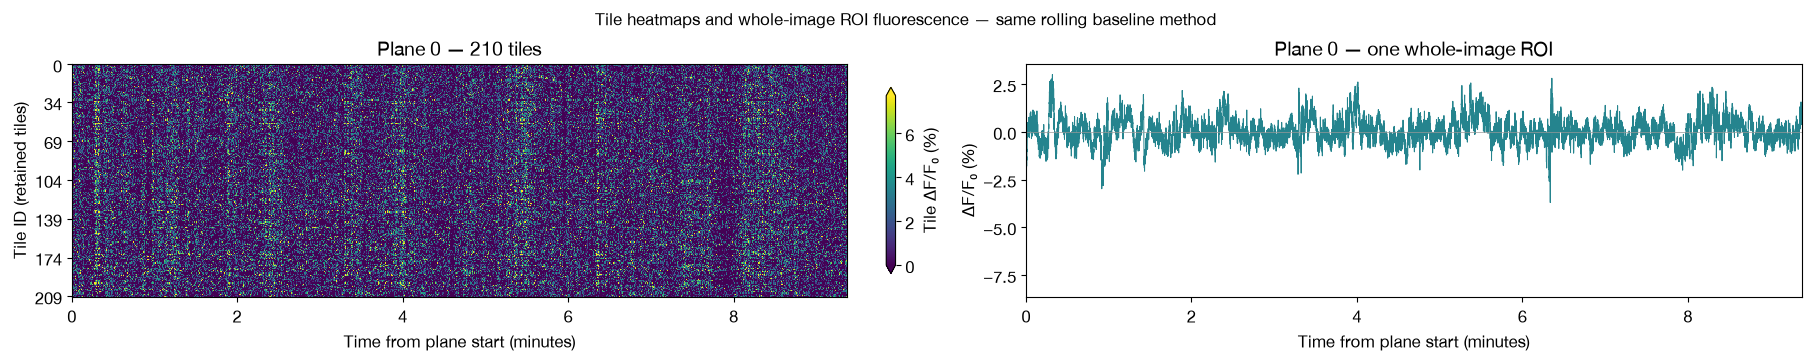

Saved: /Users/megyoung/mini2p-preprocessing/results/passive2/suite2p/tile_heatmaps_vs_whole_image_dff.png


In [6]:
# Run after the heatmap cell. One ROI spans the entire valid registered crop.
# Average fluorescence first, then compute its own baseline and ΔF/F₀.
import json
import pandas as pd

whole_image_results = []
for plane, plane_dir, values, minutes in heatmap_data:
    ops = np.load(plane_dir / 'ops.npy', allow_pickle=True).item()
    metadata = json.loads((plane_dir / 'tile_fluorescence_dff.json').read_text())
    with np.load(plane_dir / 'tile_fluorescence_dff.npz') as saved:
        bad = saved['badframes'].astype(bool)
        time_s = saved['time_s']
    binary_path = plane_dir / 'data.bin'
    if not binary_path.is_file():
        binary_path = Path(ops['reg_file'])
    nframes, height, width = int(ops['nframes']), int(ops['Ly']), int(ops['Lx'])
    y0, y1 = map(int, ops['yrange'])
    x0, x1 = map(int, ops['xrange'])
    if not (0 <= y0 < y1 <= height and 0 <= x0 < x1 <= width):
        raise ValueError('Invalid registered crop')
    if len(time_s) != nframes or len(bad) != nframes:
        raise ValueError('Saved traces do not match the registered movie')
    movie = np.memmap(binary_path, dtype=np.int16, mode='r', shape=(nframes, height, width))
    F_image = np.empty(nframes, dtype=np.float64)
    for start in range(0, nframes, 100):
        stop = min(start+100, nframes)
        F_image[start:stop] = movie[start:stop, y0:y1, x0:x1].mean(axis=(1, 2), dtype=np.float64)
    del movie
    baseline_input = F_image.copy()
    baseline_input[bad | ~np.isfinite(baseline_input)] = np.nan
    F0_image = (pd.Series(baseline_input)
        .rolling(int(metadata['baseline_window_frames']), center=True,
                 min_periods=int(metadata['baseline_min_valid_samples']))
        .quantile(float(metadata['baseline_percentile'])/100).to_numpy())
    dff_image = np.full(nframes, np.nan)
    np.divide(F_image-F0_image, F0_image, out=dff_image,
              where=np.isfinite(F0_image) & (F0_image > 0) & ~bad)
    np.savez_compressed(plane_dir / 'whole_image_roi_dff.npz', F=F_image, F0=F0_image,
                        dff=dff_image, time_s=time_s, badframes=bad,
                        roi_bounds_yxyx=np.array([y0, y1, x0, x1]))
    (plane_dir / 'whole_image_roi_dff.json').write_text(json.dumps({
        'roi': 'entire valid registered crop, including partial tile edges',
        'roi_bounds_yxyx': [y0, y1, x0, x1],
        'calculation': 'average pixels first, then compute rolling F0 and (F-F0)/F0',
        'baseline_window_frames': int(metadata['baseline_window_frames']),
        'baseline_percentile': float(metadata['baseline_percentile']),
        'baseline_min_valid_samples': int(metadata['baseline_min_valid_samples']),
        'baseline_centered': True, 'dff_units': 'fraction',
        'registered_binary': str(binary_path),
    }, indent=2))
    whole_image_results.append((plane, dff_image))

fig, axes = plt.subplots(N_PLANES, 2, figsize=(18, 3.5*N_PLANES),
                         constrained_layout=True, squeeze=False)
for row, ((plane, plane_dir, values, minutes), (_, dff_image)) in enumerate(zip(heatmap_data, whole_image_results)):
    im = draw_tile_heatmap(axes[row, 0], plane, values, minutes)
    ax = axes[row, 1]
    ax.plot(minutes, dff_image*100, color=plt.get_cmap('viridis')(0.45), linewidth=0.7)
    ax.axhline(0, color='0.6', linewidth=0.5)
    ax.set_xlim(axes[row, 0].get_xlim())
    ax.set_title(f'Plane {plane} — one whole-image ROI')
    ax.set_xlabel('Time from plane start (minutes)')
    ax.set_ylabel('ΔF/F₀ (%)')
fig.colorbar(im, ax=list(axes[:, 0]), label='Tile ΔF/F₀ (%)', extend='both', shrink=0.8)
fig.suptitle('Tile heatmaps and whole-image ROI fluorescence — same rolling baseline method')
whole_image_comparison_path = OUTPUT_DIR / SUITE2P_SAVE_FOLDER / 'tile_heatmaps_vs_whole_image_dff.png'
fig.savefig(whole_image_comparison_path, dpi=180)
plt.show()
plt.close(fig)
print('Saved:', whole_image_comparison_path)


## Raw whole-FOV fluorescence and stable-baseline comparison
Compare the saved current baseline with a fixed full-recording 10th percentile and 180-/300-second rolling baselines using the current percentile. Raw F is the mean across the valid registered image crop, before baseline normalization. Bad frames remain missing. All ΔF/F panels share limits; no smoothing or trial-baseline subtraction is applied. The table compares amplitudes on identical valid samples (pp = percentage points); correlation measures overall waveform similarity, not specifically low-frequency power. Longer rolling windows use shorter support at recording edges. A fixed baseline retains bleaching/drift as well as biological fluctuations. Figures are displayed only; existing outputs are unchanged.


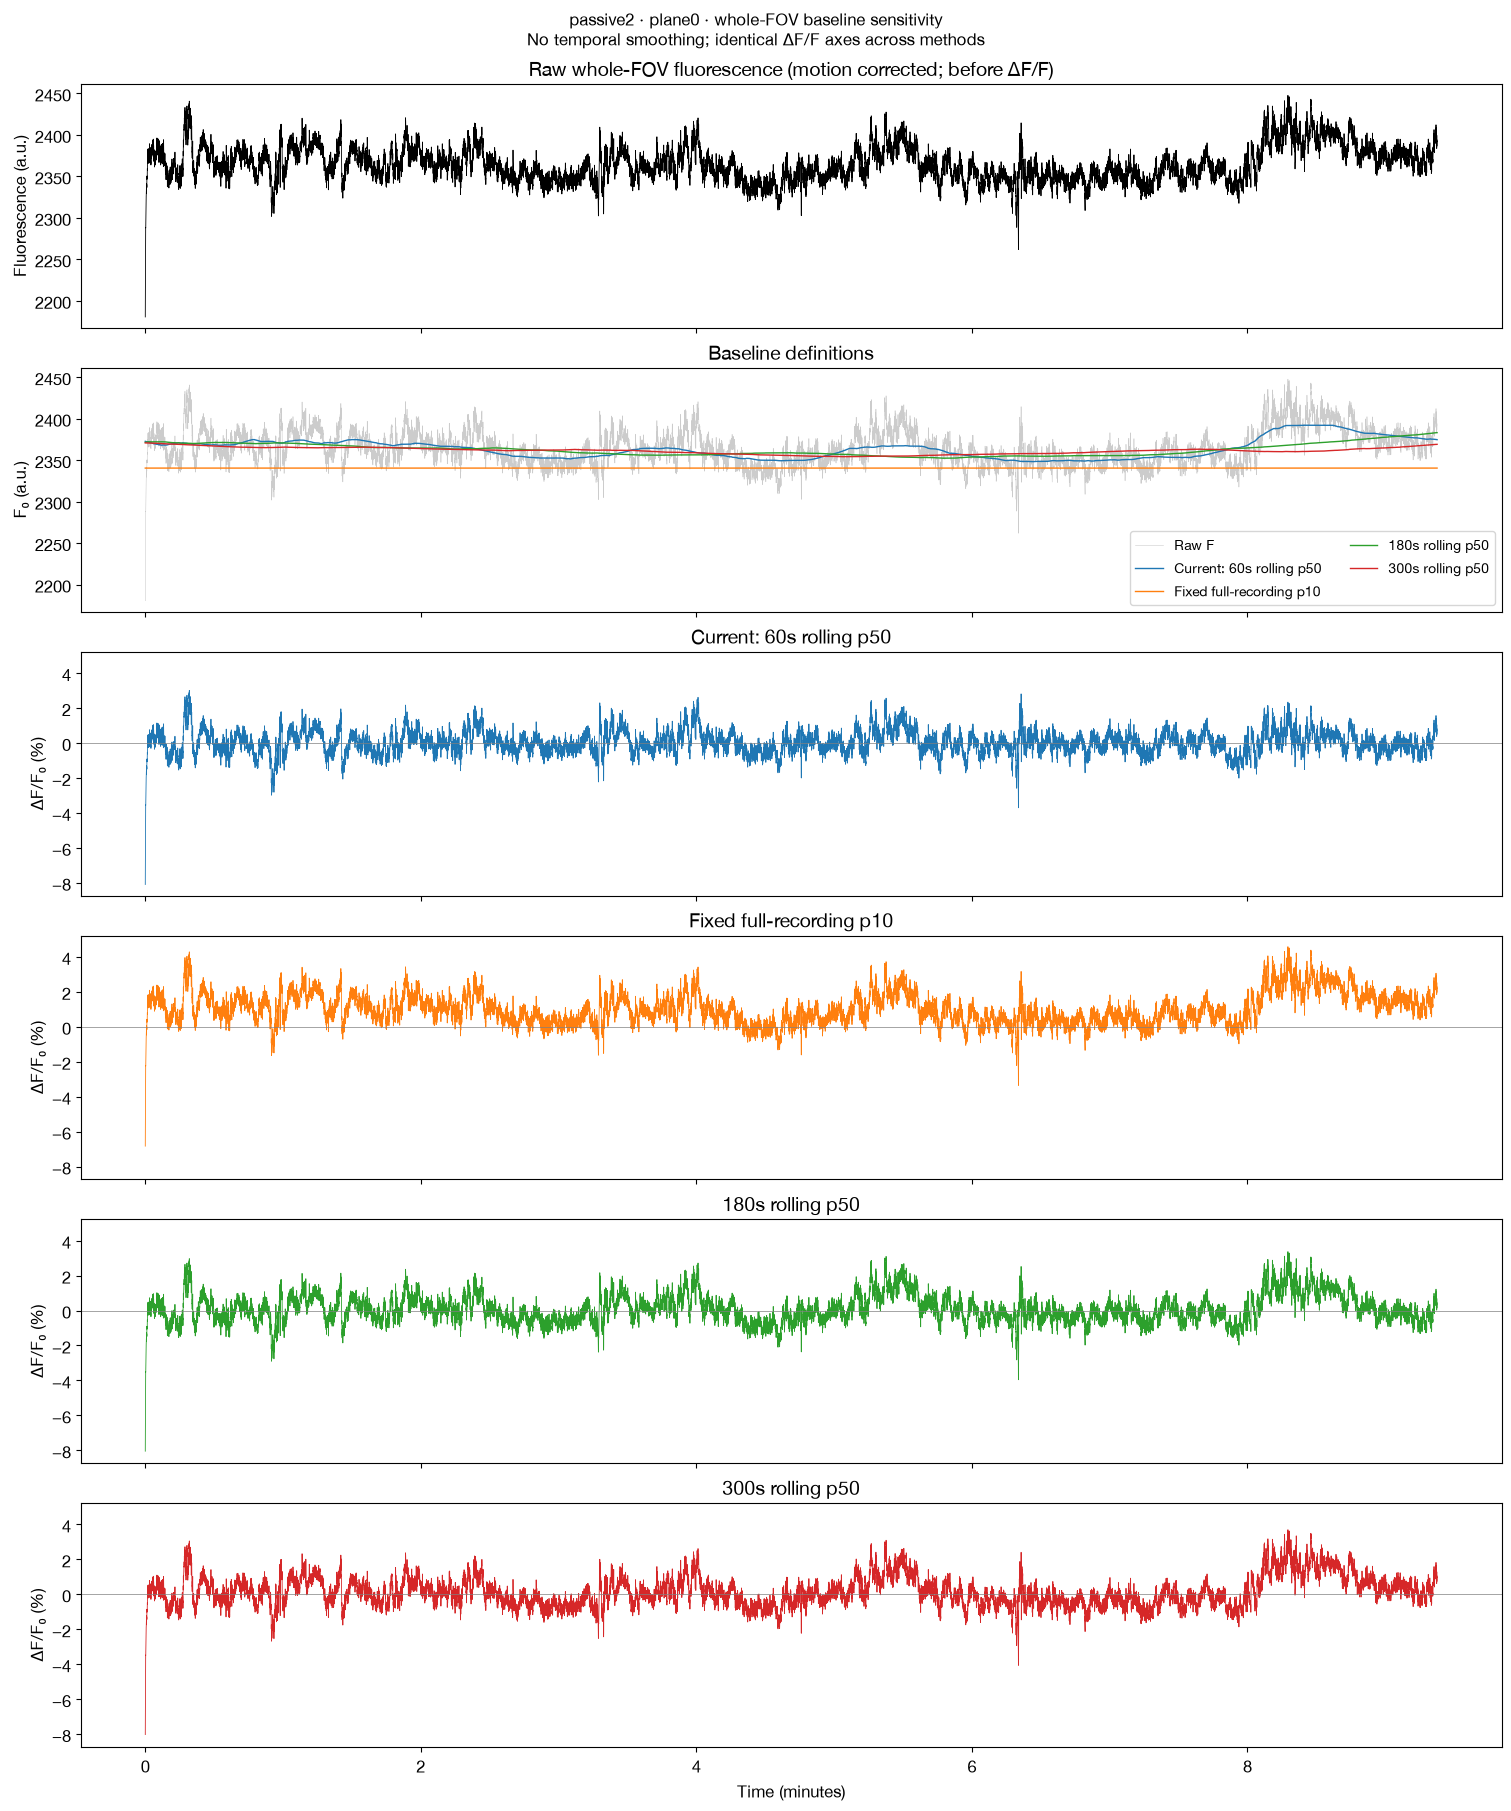

,plane,method,median_percent,p95_minus_p5_pp,std_pp,correlation_with_current,shared_samples
0,plane0,Current: 60s rolling p50,0.000000,2.165463,0.677375,1.000000,16898
1,plane0,Fixed full-recording p10,0.934778,2.864355,0.893757,0.835079,16898
2,plane0,180s rolling p50,0.004788,2.628109,0.816466,0.917862,16898
3,plane0,300s rolling p50,0.038639,2.822832,0.867768,0.862976,16898


In [7]:
# Run after whole-image ROI extraction. Display only: no files are saved.
import sys, importlib
from pathlib import Path
from IPython.display import display
import matplotlib.pyplot as plt
sys.path.insert(0, '/Users/megyoung/mini2p-preprocessing/scripts')
import compare_whole_fov_baselines as fov_baselines
importlib.reload(fov_baselines)
FOV_BASELINE_ROOT = OUTPUT_DIR / SUITE2P_SAVE_FOLDER
FOV_FIXED_PERCENTILE = 10
FOV_LONG_WINDOWS_S = (180, 300)
fov_baseline_figures, fov_baseline_metrics = fov_baselines.compare_whole_fov(
    FOV_BASELINE_ROOT, fixed_percentile=FOV_FIXED_PERCENTILE,
    windows_s=FOV_LONG_WINDOWS_S)
for figure in fov_baseline_figures:
    display(figure)
    plt.close(figure)
display(fov_baseline_metrics)


## Separate whole-image ROI plot and tile heatmaps at minutes 1–2

The first figure shows each plane’s whole-image ROI over the full recording with a shared y-axis scale. The second shows all tiles between minutes 4 and 5, retaining the full-recording viridis color limits for comparison. No additional smoothing or baseline recomputation is applied.

Zoom limits must lie inside each plane’s saved time range. If the requested interval is unavailable, the full-duration ROI figure is still saved and the zoom figures are skipped with an explanation. No different interval is substituted.


Whole-image ROI shared 1st–99th percentile limits: -1.449 to 1.854%


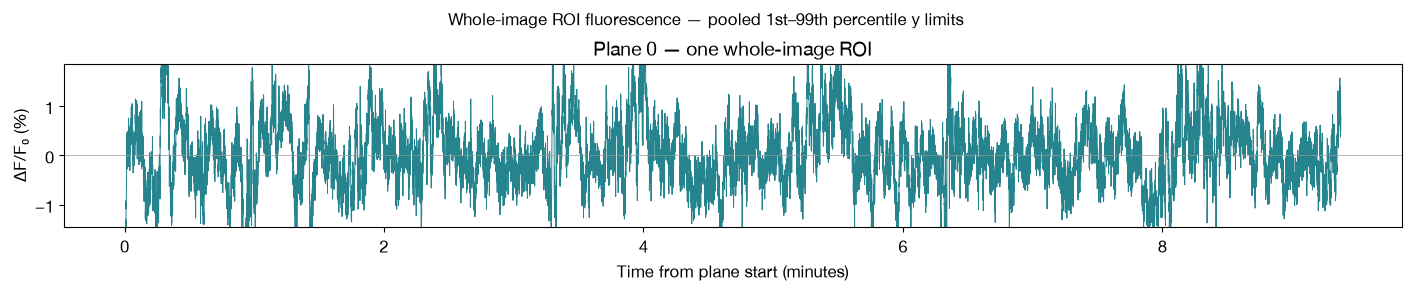

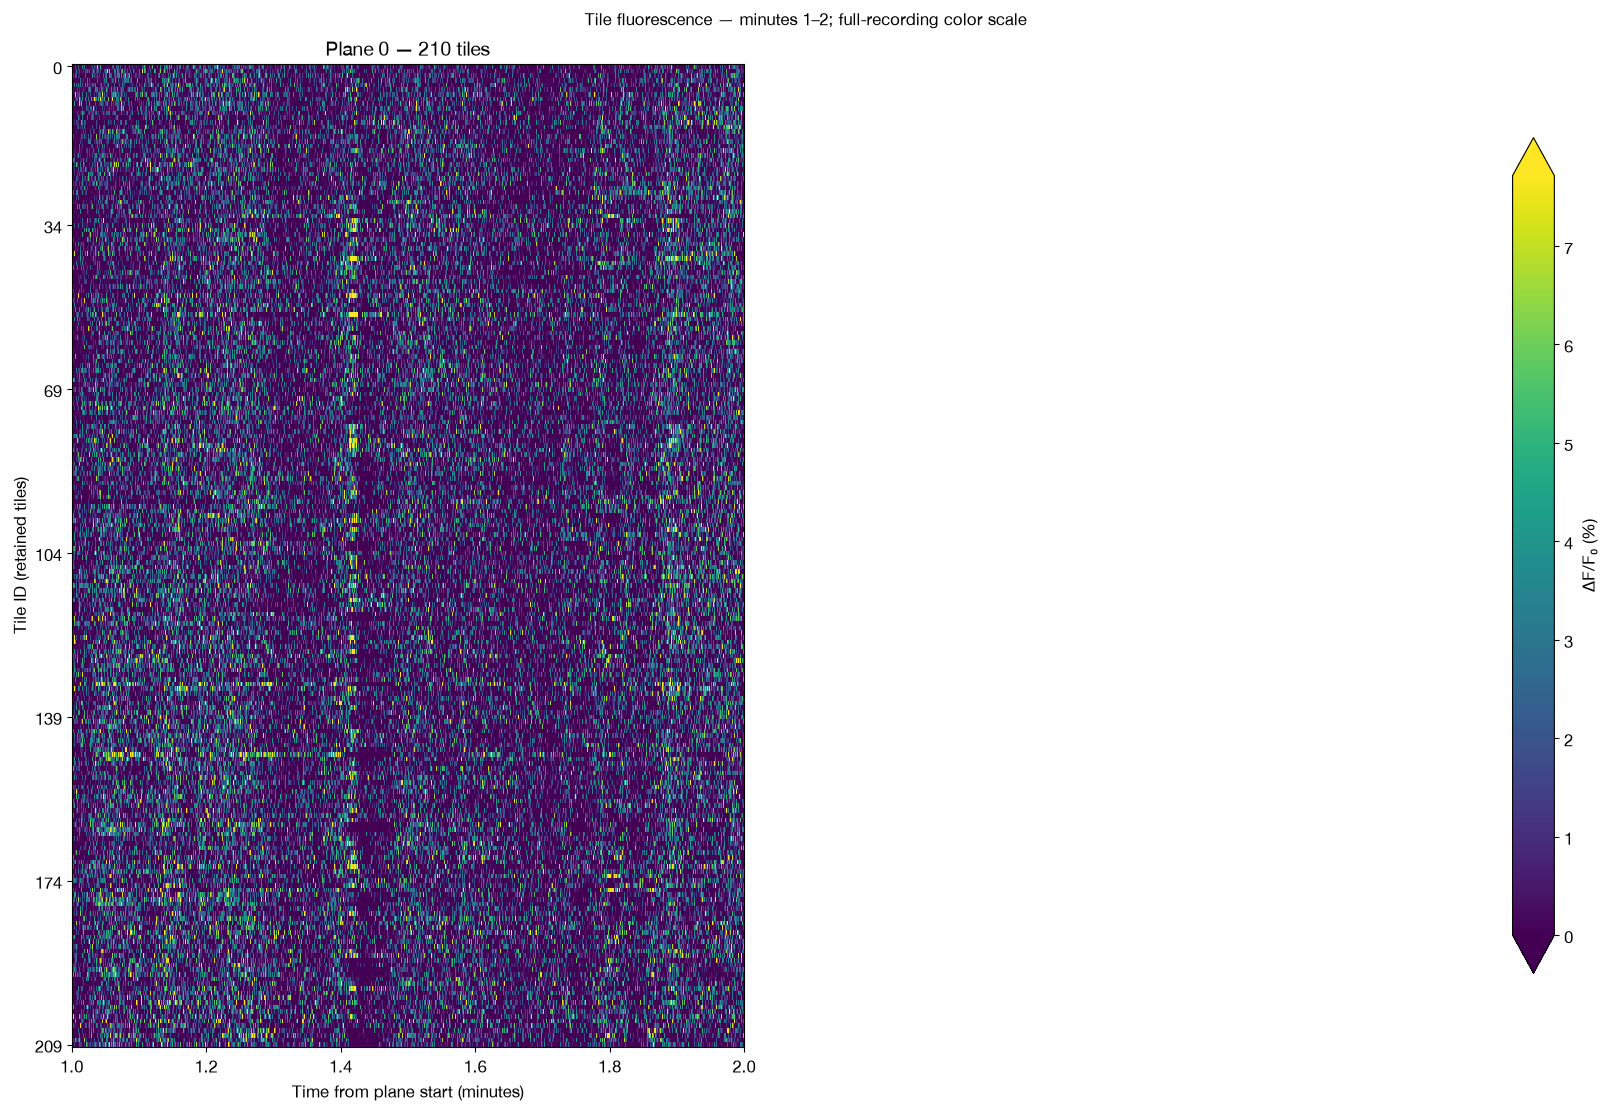

Saved: /Users/megyoung/mini2p-preprocessing/results/passive2/suite2p/whole_image_roi_dff_all_planes.png
Saved: /Users/megyoung/mini2p-preprocessing/results/passive2/suite2p/tile_dff_heatmaps_1_to_2_min.png


In [30]:
# Separate whole-image ROI traces and tile heatmaps for minutes 1–2.
# Reads existing saved arrays; no registration or fluorescence recomputation.
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

ZOOM_START_MIN = 1.0
ZOOM_STOP_MIN = 2.0
if ZOOM_STOP_MIN <= ZOOM_START_MIN:
    raise ValueError('Zoom stop must be later than zoom start')
figure_dir = OUTPUT_DIR / SUITE2P_SAVE_FOLDER
plane_plot_data = []
for plane in range(N_PLANES):
    plane_dir = figure_dir / f'plane{plane}'
    with np.load(plane_dir / 'tile_fluorescence_dff.npz') as saved:
        tiles = saved['dff'] * 100
        tile_minutes = saved['time_s'] / 60
    with np.load(plane_dir / 'whole_image_roi_dff.npz') as saved:
        roi = saved['dff'] * 100
        roi_minutes = saved['time_s'] / 60
    if tiles.shape[1] != len(tile_minutes) or len(roi) != len(roi_minutes):
        raise ValueError(f'Invalid time axes for plane {plane}')
    plane_plot_data.append((plane, tiles, tile_minutes, roi, roi_minutes))

def check_zoom_interval(data, start, stop):
    """Require at least two tile and ROI samples per plane; never shift the window."""
    if not np.isfinite(start) or not np.isfinite(stop) or stop <= start:
        raise ValueError('Zoom bounds must be finite, with stop later than start')
    available = True
    for plane, tiles, tile_minutes, roi, roi_minutes in data:
        for kind, times in [('tiles', tile_minutes), ('whole-image ROI', roi_minutes)]:
            if not len(times):
                print(f'Plane {plane} {kind}: no saved samples')
                available = False
                continue
            count = np.count_nonzero((times >= start) & (times <= stop))
            if count < 2 or start < times[0] or stop > times[-1]:
                print(f'Plane {plane} {kind}: available {times[0]:.3f}–{times[-1]:.3f} min; '
                      f'requested {start:g}–{stop:g} min ({count} samples).')
                available = False
    if not available:
        print('Zoom plots skipped. Set ZOOM_START_MIN and ZOOM_STOP_MIN within the '
              'available range, then rerun this cell and the following comparison cell.')
    return available

zoom_available = check_zoom_interval(plane_plot_data, ZOOM_START_MIN, ZOOM_STOP_MIN)

# Shared robust limits from all finite whole-image ROI responses (%).
roi_finite = np.concatenate([roi[np.isfinite(roi)]
                             for _, _, _, roi, _ in plane_plot_data])
if not roi_finite.size:
    raise ValueError('No finite whole-image ROI responses')
roi_ymin, roi_ymax = np.percentile(roi_finite, [1, 99])
if roi_ymax <= roi_ymin:
    roi_ymin, roi_ymax = roi_ymin-0.5, roi_ymax+0.5
print(f'Whole-image ROI shared 1st–99th percentile limits: {roi_ymin:.3f} to {roi_ymax:.3f}%')

fig, axes = plt.subplots(N_PLANES, 1, figsize=(14, 2.8*N_PLANES),
                         sharex=True, sharey=True, constrained_layout=True, squeeze=False)
for ax, (plane, tiles, tile_minutes, roi, roi_minutes) in zip(axes[:, 0], plane_plot_data):
    ax.plot(roi_minutes, roi, color=plt.get_cmap('viridis')(0.45), linewidth=0.7)
    ax.axhline(0, color='0.6', linewidth=0.5)
    ax.set_title(f'Plane {plane} — one whole-image ROI')
    ax.set_ylim(roi_ymin, roi_ymax)
    ax.set_ylabel('ΔF/F₀ (%)')
axes[-1, 0].set_xlabel('Time from plane start (minutes)')
fig.suptitle('Whole-image ROI fluorescence — pooled 1st–99th percentile y limits')
whole_roi_figure = figure_dir / 'whole_image_roi_dff_all_planes.png'
fig.savefig(whole_roi_figure, dpi=180)
plt.show()
plt.close(fig)

# Keep the same 0-to-99th-percentile color limits as the full-duration heatmaps.
color_min = float(globals().get('HEATMAP_MIN_PERCENT', 0.0))
color_max_setting = globals().get('HEATMAP_LIMIT_PERCENT', None)
if color_max_setting is None:
    finite = np.concatenate([np.abs(a[np.isfinite(a)]) for _, a, _, _, _ in plane_plot_data])
    if not finite.size:
        raise ValueError('No finite tile values')
    color_max = float(np.percentile(finite, globals().get('HEATMAP_ABS_PERCENTILE', 99)))
    del finite
else:
    color_max = float(color_max_setting)
if not np.isfinite(color_min+color_max) or color_max <= color_min:
    raise ValueError('Invalid heatmap color limits')
cmap_zoom = plt.get_cmap('viridis').copy()
cmap_zoom.set_bad('lightgray')
if zoom_available:
    fig, axes = plt.subplots(int(np.ceil(N_PLANES/2)), 2, figsize=(16, 11),
                             constrained_layout=True, squeeze=False)
    for ax, (plane, tiles, minutes, roi, roi_minutes) in zip(axes.flat, plane_plot_data):
        selected = (minutes >= ZOOM_START_MIN) & (minutes <= ZOOM_STOP_MIN)
        if selected.sum() < 2:
            raise ValueError(f'Plane {plane} has fewer than two samples in zoom interval')
        times = minutes[selected]
        dt = np.median(np.diff(minutes))
        im = ax.imshow(np.ma.masked_invalid(tiles[:, selected]), origin='upper', aspect='auto',
                       interpolation='nearest', cmap=cmap_zoom, vmin=color_min, vmax=color_max,
                       extent=[times[0]-dt/2, times[-1]+dt/2, tiles.shape[0]-0.5, -0.5])
        ax.set_xlim(ZOOM_START_MIN, ZOOM_STOP_MIN)
        ax.set_title(f'Plane {plane} — {tiles.shape[0]} tiles')
        ax.set_xlabel('Time from plane start (minutes)')
        label_tile_axis(ax, figure_dir / f'plane{plane}')
    for ax in list(axes.flat)[N_PLANES:]:
        ax.set_visible(False)
    fig.colorbar(im, ax=list(axes.flat), label='ΔF/F₀ (%)', extend='both', shrink=0.85)
    fig.suptitle(f'Tile fluorescence — minutes {ZOOM_START_MIN:g}–{ZOOM_STOP_MIN:g}; full-recording color scale')
    zoom_heatmap_figure = figure_dir / f'tile_dff_heatmaps_{ZOOM_START_MIN:g}_to_{ZOOM_STOP_MIN:g}_min.png'
    fig.savefig(zoom_heatmap_figure, dpi=180)
    plt.show()
    plt.close(fig)
print('Saved:', whole_roi_figure)
if zoom_available:
    print('Saved:', zoom_heatmap_figure)


## Minutes 1–2: ROI percentile limits and combined comparison

Run after the preceding plot cell. Both figures use pooled 1st–99th percentile limits from whole-image ROI responses within the selected window, shared across all planes. Tile heatmaps retain their existing viridis color limits. Percentiles affect display only; baseline and saved traces are unchanged.


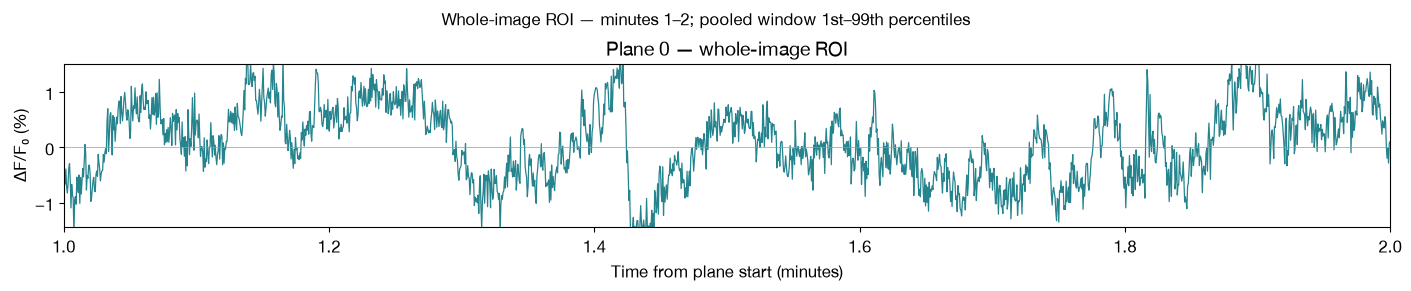

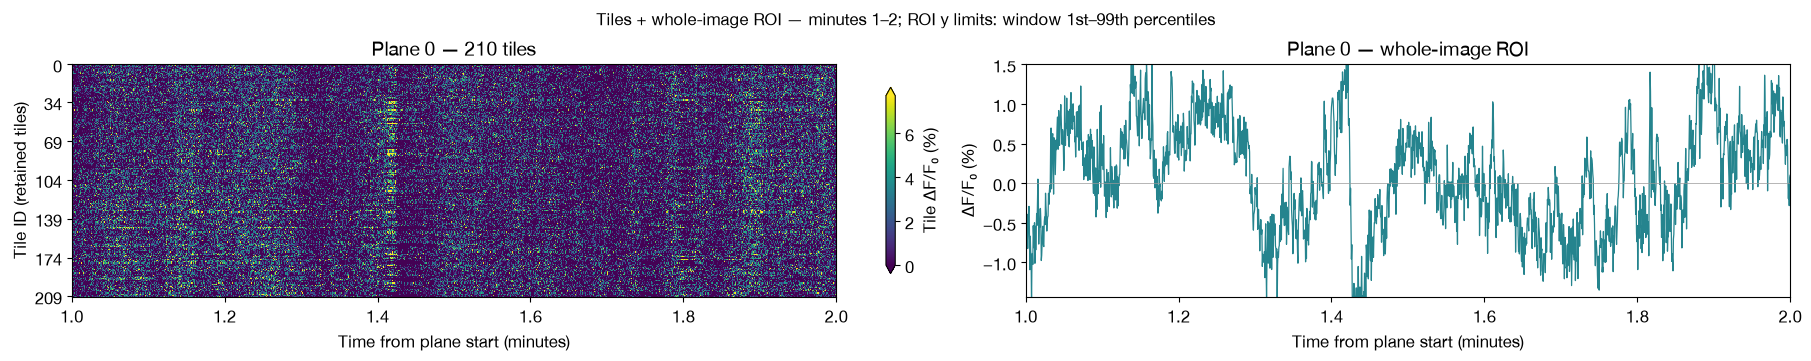

ROI window percentile limits: -1.435 to 1.506%
Saved: /Users/megyoung/mini2p-preprocessing/results/passive2/suite2p/whole_image_roi_dff_1_to_2_min.png
Saved: /Users/megyoung/mini2p-preprocessing/results/passive2/suite2p/tiles_vs_whole_image_dff_1_to_2_min.png


In [31]:
# Window-specific percentile limits; retain the existing tile color scale.
# Recheck in case the window settings changed after the preceding cell.
zoom_available = check_zoom_interval(plane_plot_data, ZOOM_START_MIN, ZOOM_STOP_MIN)
if zoom_available:
    zoom_roi_values = np.concatenate([
        roi[(minutes >= ZOOM_START_MIN) & (minutes <= ZOOM_STOP_MIN) & np.isfinite(roi)]
        for _, _, _, roi, minutes in plane_plot_data
    ])
    if not zoom_roi_values.size:
        raise ValueError('No finite whole-image ROI values in the selected window')
    zoom_ymin, zoom_ymax = np.percentile(zoom_roi_values, [1, 99])
    if zoom_ymax <= zoom_ymin:
        zoom_ymin, zoom_ymax = zoom_ymin-0.5, zoom_ymax+0.5
    
    def draw_zoom_roi(ax, plane, roi, minutes):
        selected = (minutes >= ZOOM_START_MIN) & (minutes <= ZOOM_STOP_MIN)
        if selected.sum() < 2:
            raise ValueError(f'Insufficient ROI samples for plane {plane}')
        ax.plot(minutes[selected], roi[selected], color=plt.get_cmap('viridis')(0.45), linewidth=0.9)
        ax.axhline(0, color='0.6', linewidth=0.5)
        ax.set(xlim=(ZOOM_START_MIN, ZOOM_STOP_MIN), ylim=(zoom_ymin, zoom_ymax),
               title=f'Plane {plane} — whole-image ROI', ylabel='ΔF/F₀ (%)',
               xlabel='Time from plane start (minutes)')
    
    fig, axes = plt.subplots(N_PLANES, 1, figsize=(14, 2.8*N_PLANES),
                             sharex=True, sharey=True, constrained_layout=True, squeeze=False)
    for ax, (plane, tiles, minutes, roi, roi_minutes) in zip(axes[:, 0], plane_plot_data):
        draw_zoom_roi(ax, plane, roi, roi_minutes)
    fig.suptitle(f'Whole-image ROI — minutes {ZOOM_START_MIN:g}–{ZOOM_STOP_MIN:g}; pooled window 1st–99th percentiles')
    zoom_roi_path = figure_dir / f'whole_image_roi_dff_{ZOOM_START_MIN:g}_to_{ZOOM_STOP_MIN:g}_min.png'
    fig.savefig(zoom_roi_path, dpi=180)
    plt.show()
    plt.close(fig)
    
    fig, axes = plt.subplots(N_PLANES, 2, figsize=(18, 3.5*N_PLANES),
                             constrained_layout=True, squeeze=False)
    for row, (plane, tiles, minutes, roi, roi_minutes) in enumerate(plane_plot_data):
        selected = (minutes >= ZOOM_START_MIN) & (minutes <= ZOOM_STOP_MIN)
        if selected.sum() < 2:
            raise ValueError(f'Insufficient tile samples for plane {plane}')
        times = minutes[selected]
        dt = np.median(np.diff(minutes))
        im = axes[row, 0].imshow(np.ma.masked_invalid(tiles[:, selected]),
            origin='upper', aspect='auto', interpolation='nearest', cmap=cmap_zoom,
            vmin=color_min, vmax=color_max,
            extent=[times[0]-dt/2, times[-1]+dt/2, tiles.shape[0]-0.5, -0.5])
        axes[row, 0].set(xlim=(ZOOM_START_MIN, ZOOM_STOP_MIN),
            title=f'Plane {plane} — {tiles.shape[0]} tiles', ylabel='Tile ID',
            xlabel='Time from plane start (minutes)')
        label_tile_axis(axes[row, 0], figure_dir / f'plane{plane}')
        draw_zoom_roi(axes[row, 1], plane, roi, roi_minutes)
    fig.colorbar(im, ax=list(axes[:, 0]), label='Tile ΔF/F₀ (%)', extend='both', shrink=0.8)
    fig.suptitle(f'Tiles + whole-image ROI — minutes {ZOOM_START_MIN:g}–{ZOOM_STOP_MIN:g}; ROI y limits: window 1st–99th percentiles')
    zoom_comparison_path = figure_dir / f'tiles_vs_whole_image_dff_{ZOOM_START_MIN:g}_to_{ZOOM_STOP_MIN:g}_min.png'
    fig.savefig(zoom_comparison_path, dpi=180)
    plt.show()
    plt.close(fig)
    print(f'ROI window percentile limits: {zoom_ymin:.3f} to {zoom_ymax:.3f}%')
    print('Saved:', zoom_roi_path)
    print('Saved:', zoom_comparison_path)


## Registered multi-plane video with tile grids

All configured planes are arranged horizontally at the per-plane sampling rate. For a one-plane acquisition the video contains only plane 0. Cyan grid lines are translucent; contrast is fixed separately per plane. A centered 20-frame rolling average is applied separately to each plane. The source is registered fluorescence intensity. Bad frames are retained and labeled.


In [32]:
# Registered movies: one or four planes horizontally, with saved tile bounds overlaid.
# Playback at acquisition volume rate; centered rolling average, 20 frames per plane.
from pathlib import Path
import json
import subprocess
import numpy as np
import imageio_ffmpeg
from PIL import Image, ImageDraw, ImageFont

VIDEO_WINDOW_FRAMES = 20
VIDEO_START_MIN = 1
VIDEO_STOP_MIN = 2
VIDEO_GRID_OPACITY = 0.45
VIDEO_BLACK_PERCENTILE = 1.0
VIDEO_WHITE_PERCENTILE = 99.5
VIDEO_OUTPUT_DIR = OUTPUT_DIR / SUITE2P_SAVE_FOLDER / 'videos'
VIDEO_OUTPUT_DIR.mkdir(exist_ok=True)
video_path = VIDEO_OUTPUT_DIR / f'registered_{N_PLANES}plane_grid_rolling{VIDEO_WINDOW_FRAMES}_{VIDEO_START_MIN:g}_to_{VIDEO_STOP_MIN:g}_min.mp4'

movies, bounds_list, times_list, bad_list, rate_list = [], [], [], [], []
for plane in range(N_PLANES):
    plane_dir = OUTPUT_DIR / SUITE2P_SAVE_FOLDER / f'plane{plane}'
    ops = np.load(plane_dir / 'ops.npy', allow_pickle=True).item()
    meta = json.loads((plane_dir / 'tile_fluorescence_dff.json').read_text())
    rate_list.append(float(meta['fs_hz']))
    binary_path = plane_dir / 'data.bin'
    if not binary_path.is_file():
        binary_path = Path(ops['reg_file'])
    movies.append(np.memmap(binary_path, dtype=np.int16, mode='r',
                  shape=(int(ops['nframes']), int(ops['Ly']), int(ops['Lx']))))
    with np.load(plane_dir / 'tile_fluorescence_dff.npz') as saved:
        bounds_list.append(saved['tile_bounds_yxyx'])
        times_list.append(saved['time_s'])
        bad_list.append(saved['badframes'].astype(bool))
if not np.allclose(rate_list, rate_list[0]):
    raise ValueError('Plane sampling rates differ')
video_fps = rate_list[0]
indices = np.flatnonzero((times_list[0] >= VIDEO_START_MIN*60) &
                         (times_list[0] < VIDEO_STOP_MIN*60))
if not len(indices):
    raise ValueError('No frames in video interval')
for movie, times in zip(movies, times_list):
    if len(times) != len(movie) or not np.allclose(times, times_list[0]):
        raise ValueError('Plane time axes do not match')
height, width = movies[0].shape[1:]
if any(movie.shape[1:] != (height, width) for movie in movies):
    raise ValueError('Plane image dimensions differ')

# A 20-frame window uses frames i-9 through i+10 at output timestamp i.
# Source frames outside the displayed minute support its boundary windows.
window = int(VIDEO_WINDOW_FRAMES)
if window < 1 or window != VIDEO_WINDOW_FRAMES:
    raise ValueError('VIDEO_WINDOW_FRAMES must be a positive integer')
left = (window-1)//2
right = window-1-left
if indices[0]-left < 0 or indices[-1]+right >= min(len(m) for m in movies):
    raise ValueError('Insufficient source frames for full rolling windows')

def rolling_frame(movie, index):
    return movie[index-left:index+right+1].mean(axis=0, dtype=np.float32)

# Fixed display contrast per plane across the full selected minute.
limits, masks = [], []
samples = indices[np.linspace(0, len(indices)-1, min(100, len(indices)), dtype=int)]
for movie, bounds in zip(movies, bounds_list):
    pixels = np.concatenate([rolling_frame(movie, i)[::4, ::4].ravel() for i in samples])
    low, high = np.percentile(pixels, [VIDEO_BLACK_PERCENTILE, VIDEO_WHITE_PERCENTILE])
    if high <= low:
        raise ValueError('Invalid video contrast range')
    limits.append((float(low), float(high)))
    grid = Image.new('L', (width, height), 0)
    draw = ImageDraw.Draw(grid)
    for ya, yb, xa, xb in bounds:
        draw.rectangle((int(xa), int(ya), int(xb)-1, int(yb)-1), outline=255, width=1)
    masks.append(np.asarray(grid) > 0)

header_height = 40
video_size = (width*N_PLANES, height+header_height)
if any(size % 2 for size in video_size):
    raise ValueError('H.264 output dimensions must be even')
try:
    font = ImageFont.truetype('DejaVuSans.ttf', 18)
except OSError:
    font = ImageFont.load_default()
writer = imageio_ffmpeg.write_frames(str(video_path), video_size, fps=video_fps,
    codec='libx264', pix_fmt_in='rgb24', pix_fmt_out='yuv420p', macro_block_size=1,
    output_params=['-crf', '18', '-preset', 'medium', '-movflags', '+faststart'])
writer.send(None)
running_sums = [movie[indices[0]-left:indices[0]+right+1].sum(axis=0, dtype=np.float64)
                for movie in movies]
try:
    for output_index, frame_index in enumerate(indices):
        canvas = np.zeros((height+header_height, width*N_PLANES, 3), dtype=np.uint8)
        for plane, (movie, mask, (low, high)) in enumerate(zip(movies, masks, limits)):
            if output_index:
                running_sums[plane] += movie[frame_index+right]
                running_sums[plane] -= movie[frame_index-left-1]
            averaged = running_sums[plane] / window
            gray = np.round(np.clip((averaged-low)/(high-low), 0, 1)*255).astype(np.uint8)
            rgb = np.repeat(gray[..., None], 3, axis=2)
            rgb[mask] = np.round((1-VIDEO_GRID_OPACITY)*rgb[mask] +
                                VIDEO_GRID_OPACITY*np.array([0, 255, 255])).astype(np.uint8)
            canvas[header_height:, plane*width:(plane+1)*width] = rgb
        frame_image = Image.fromarray(canvas)
        draw = ImageDraw.Draw(frame_image)
        source_s = float(times_list[0][frame_index])
        label_time = f'{int(source_s//60):02d}:{source_s%60:05.2f}'
        for plane in range(N_PLANES):
            flag = '  BAD FRAME IN WINDOW' if bad_list[plane][frame_index-left:frame_index+right+1].any() else ''
            draw.text((plane*width+10, 10), f'Plane {plane}   {label_time}   avg{window}{flag}',
                      fill=(255, 255, 255), font=font)
        writer.send(np.asarray(frame_image))
        if output_index == 0:
            frame_image.save(video_path.with_suffix('.png'))
finally:
    writer.close()
subprocess.run([imageio_ffmpeg.get_ffmpeg_exe(), '-v', 'error', '-i', str(video_path),
                '-f', 'null', '-'], check=True)
video_path.with_suffix('.json').write_text(json.dumps({
    'start_min': VIDEO_START_MIN, 'stop_min_exclusive': VIDEO_STOP_MIN,
    'first_frame': int(indices[0]), 'last_frame': int(indices[-1]),
    'nframes': len(indices), 'fps': video_fps, 'duration_s': len(indices)/video_fps,
    'contrast_percentiles': [VIDEO_BLACK_PERCENTILE, VIDEO_WHITE_PERCENTILE],
    'contrast_limits_per_plane': limits, 'grid_opacity': VIDEO_GRID_OPACITY,
    'source': 'registered intensity movies, not dff movies',
    'nplanes': N_PLANES,
    'synchronization': ('single plane' if N_PLANES == 1 else 'same volume index; planes acquired sequentially within volume'),
    'temporal_averaging': True, 'rolling_window_frames': window,
    'rolling_window_seconds': window/video_fps,
    'window_alignment': f'output i averages i-{left} through i+{right}',
    'bad_frame_policy': 'included in average; window labeled if any frame flagged',
}, indent=2))
print('Saved video:', video_path)
from IPython.display import Video, display
display(Video(str(video_path), embed=False))


Saved video: /Users/megyoung/mini2p-preprocessing/results/passive2/suite2p/videos/registered_1plane_grid_rolling20_1_to_2_min.mp4


## Baseline-method and window sensitivity

Compares rolling 20th-percentile F₀ against the installed Suite2p maximin baseline at 30, 60, and 120 seconds, using identical saved tile fluorescence. Maximin uses a Gaussian sigma of 10 **frames** (about 1.33 s); the code reconstructs its F₀ and explicitly computes ΔF/F₀. Bad/missing samples are interpolated only for the maximin baseline input, then excluded from both methods’ output. No neuropil subtraction or deconvolution is used. Metrics cover the full recording and an interior interval excluding the first/last 60 seconds. Representative dim, typical, bright, and high-excursion tiles are selected by stated rules; these are not validated responses. Original outputs are preserved.


In [33]:
from pathlib import Path
import runpy
comparison_script = Path('/Users/megyoung/mini2p-preprocessing/scripts/compare_tile_baselines.py')
comparison_functions = runpy.run_path(str(comparison_script))
baseline_comparison_dir = comparison_functions['compare_baselines'](
    OUTPUT_DIR / SUITE2P_SAVE_FOLDER, windows=(30, 60, 120))
from IPython.display import Image, display
display(Image(filename=str(baseline_comparison_dir / 'baseline_sensitivity_summary.png')))
for plane in range(N_PLANES):
    display(Image(filename=str(baseline_comparison_dir / f'plane{plane}_baseline_comparison.png')))


plane0 rolling_p20_30s


AssertionError: 
Not equal to tolerance rtol=1e-05, atol=1e-05

Mismatched elements: 3548580 / 3548580 (100%)
First 5 mismatches are at indices:
 [0, 0]: 2271.706298828125 (ACTUAL), 2320.076171875 (DESIRED)
 [0, 1]: 2271.73291015625 (ACTUAL), 2320.0556640625 (DESIRED)
 [0, 2]: 2271.75927734375 (ACTUAL), 2320.076171875 (DESIRED)
 [0, 3]: 2271.785888671875 (ACTUAL), 2320.0966796875 (DESIRED)
 [0, 4]: 2271.8125 (ACTUAL), 2320.076171875 (DESIRED)
Max absolute difference among violations: 109.55151
Max relative difference among violations: 0.0454899
 ACTUAL: array([[2271.7063, 2271.733 , 2271.7593, ..., 2368.813 , 2368.8042,
        2368.7952],
       [2456.1023, 2456.1177, 2456.1333, ..., 2529.4944, 2529.2751,...
 DESIRED: array([[2320.0762, 2320.0557, 2320.0762, ..., 2414.1343, 2414.128 ,
        2414.1343],
       [2512.8174, 2512.8174, 2512.8174, ..., 2577.5088, 2577.538 ,...

## Saved files

All outputs are under `results/passive2/suite2p`. Plane 0 stores F.npy, F0.npy, dff.npy, tile IDs, tile-selection metadata, and whole-image traces. Event, pupil, baseline-sensitivity, model, and video outputs use separate subfolders. `passive2_aligned_data.pkl` is a local adapter copy of all_data.pkl’s aligned_data table for the existing analysis helpers.


## Passive2 event-aligned tile responses

Uses the Stim and Reward columns in all_data.pkl → aligned_data. Stim 2 is Grating 1 and Stim 4 is Grating 2. Consecutive active samples count as one onset. Out-of-range trials are excluded.


/var/folders/g7/dhg2tq9173j2cwmlq6jvq28r0000gn/T/ipykernel_18533/1142661422.py:13: RuntimeWarning: Behavior Time contains nonfinite or nonincreasing timestamps. Using the explicitly row-aligned event positions and saved imaging time axis; behavioral rows are not sorted or dropped, and original Time values are retained in event_onsets.csv.
  event_figure = helpers['plot_event_aligned_tiles'](


{
  "Grating 1": {
    "detected": 18,
    "complete_windows": 18
  },
  "Grating 2": {
    "detected": 18,
    "complete_windows": 17
  },
  "Reward": {
    "detected": 18,
    "complete_windows": 17
  }
}
Saved: /Users/megyoung/mini2p-preprocessing/results/passive2/suite2p/event_aligned/gratings_reward_tile_dff.png


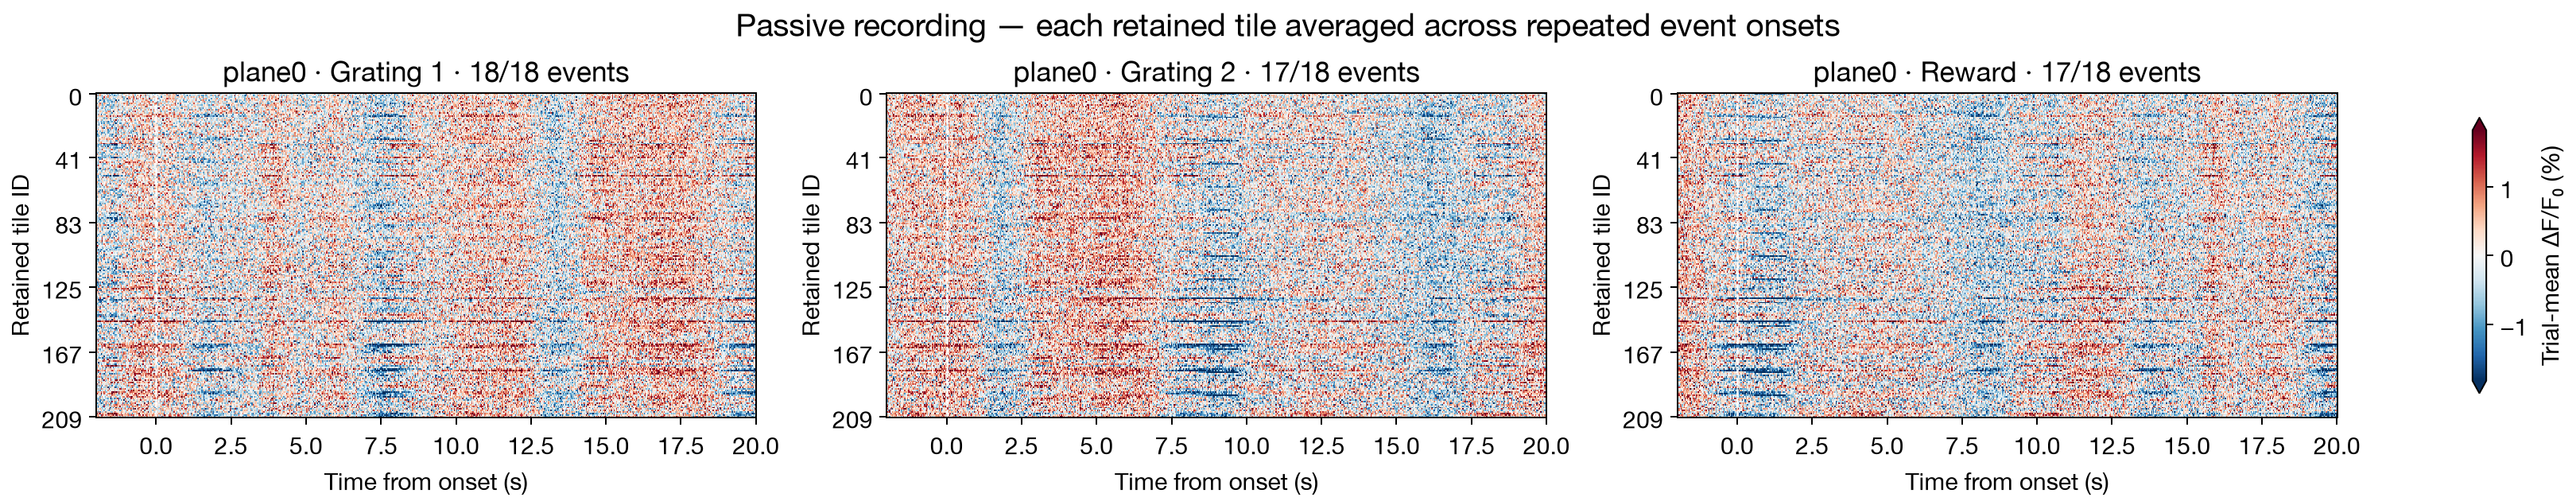

In [34]:
# Passive2 event analysis using the aligned behavior table from setup.
from pathlib import Path
import runpy
from IPython.display import Image, display
PASSIVE_EVENT_ROOT = Path('/Users/megyoung/mini2p-preprocessing/results/passive2/suite2p')
PASSIVE_TABLE = ALIGNED_TABLE_PATH
GRATING_CODES = {'Grating 1': 2, 'Grating 2': 4}
EVENT_COLOR_LIMIT_PERCENT = None  # automatic; set e.g. 5 for fixed ±5%
EVENT_COLOR_PERCENTILE = 98  # lower for stronger contrast
EVENT_PRE_S = 2.0
EVENT_POST_S = 20
helpers = runpy.run_path('/Users/megyoung/mini2p-preprocessing/scripts/plot_passive_event_aligned_tiles.py')
event_figure = helpers['plot_event_aligned_tiles'](
    PASSIVE_EVENT_ROOT, PASSIVE_TABLE, GRATING_CODES, EVENT_PRE_S, EVENT_POST_S,
    color_limit_percent=EVENT_COLOR_LIMIT_PERCENT, color_percentile=EVENT_COLOR_PERCENTILE)
display(Image(filename=str(event_figure)))


## Event alignment: original versus prestimulus-subtracted ΔF/F₀

Subtracts each trial’s −2 to 0 s mean separately for each retained tile, then averages across events. Requires 80% of prestimulus samples to be valid; a trial/tile pair failing this check is excluded from both sides of the comparison. Both use a fixed −20 to +20 blue–white–red scale. Centered values are changes in ΔF/F₀ (percentage points when plotted), not z-scores. Original saved traces remain unchanged. A negative centered response is lower than the prestimulus level, which can itself include preceding-event activity.


Saved: /Users/megyoung/mini2p-preprocessing/results/passive2/suite2p/event_aligned/gratings_reward_prestimulus_comparison.png
{
  "plane0": {
    "grating_1": {
      "trials": 18,
      "excluded_trial_tile_pairs": 0,
      "total_trial_tile_pairs": 3780,
      "minimum_prestimulus_samples": 48
    },
    "grating_2": {
      "trials": 17,
      "excluded_trial_tile_pairs": 0,
      "total_trial_tile_pairs": 3570,
      "minimum_prestimulus_samples": 48
    },
    "reward": {
      "trials": 17,
      "excluded_trial_tile_pairs": 0,
      "total_trial_tile_pairs": 3570,
      "minimum_prestimulus_samples": 48
    }
  }
}


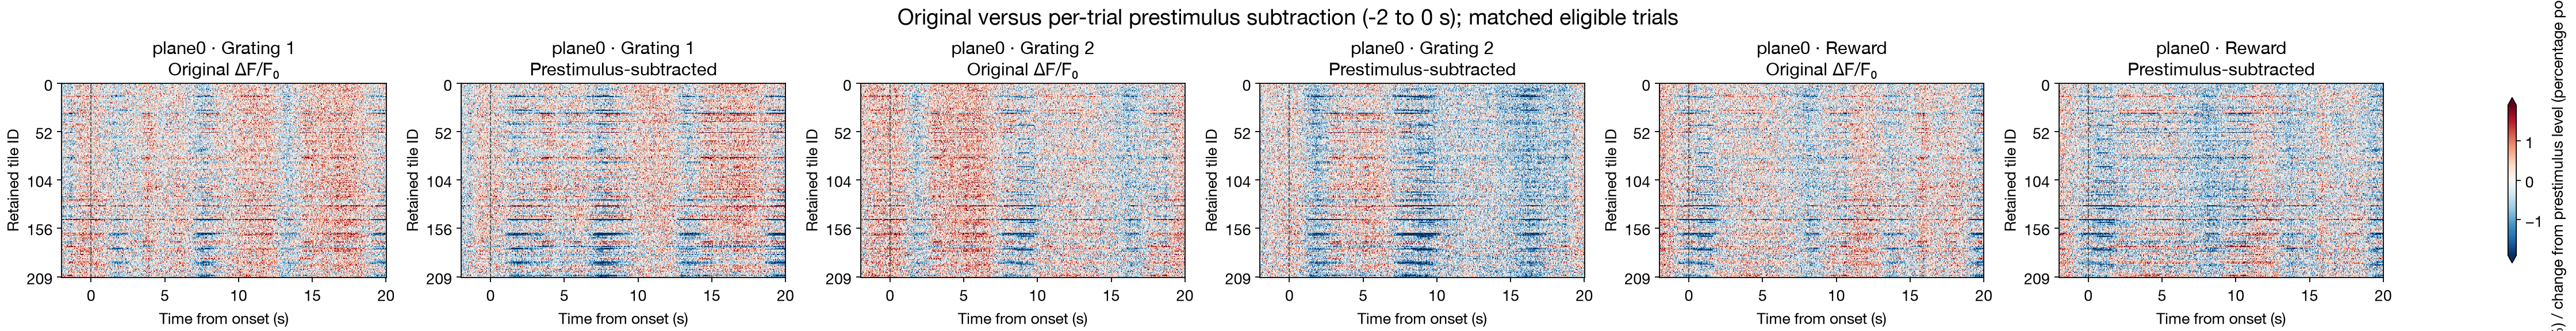

In [35]:
from pathlib import Path
import runpy
from IPython.display import Image, display
PASSIVE_EVENT_ROOT = Path('/Users/megyoung/mini2p-preprocessing/results/passive2/suite2p')
PRESTIM_BASELINE_START_S = -2.0
PRESTIM_MIN_VALID_FRACTION = 0.8
helpers = runpy.run_path('/Users/megyoung/mini2p-preprocessing/scripts/plot_passive_event_aligned_tiles.py')
comparison_figure = helpers['plot_prestimulus_comparison'](
    PASSIVE_EVENT_ROOT, PRESTIM_BASELINE_START_S, PRESTIM_MIN_VALID_FRACTION,
    color_limit_percent=EVENT_COLOR_LIMIT_PERCENT, color_percentile=EVENT_COLOR_PERCENTILE)
display(Image(filename=str(comparison_figure)))


## Passive2: ΔF/F₀ correlation with pupil diameter

Computes zero-lag Pearson r between each retained tile’s saved continuous ΔF/F₀ and the row-aligned `pupil_diameter` column. Missing/nonpositive pupil measurements, nonfinite fluorescence, and bad imaging frames are excluded pairwise; no interpolation or smoothing is applied. Requires at least 30 paired samples. The left panels map correlations to tile-grid positions (gray = excluded/undefined); right panels show whole-image ROI ΔF/F₀ versus pupil diameter. This is descriptive correlation, not evidence that pupil changes cause fluorescence changes; shared stimulus, reward, movement, or drift can contribute. No p-values based on independent time samples are reported. Outputs are a single figure, tile and whole-image CSVs, and settings under passive/suite2p/pupil_correlation.


Whole-image correlations: [{'plane': 'plane0', 'pearson_r': 0.3255126462195034, 'n_paired_frames': 16880}]
Finite pupil frames: 16880 / 16898
Saved: /Users/megyoung/mini2p-preprocessing/results/passive2/suite2p/pupil_correlation/pupil_diameter_dff_correlations.png


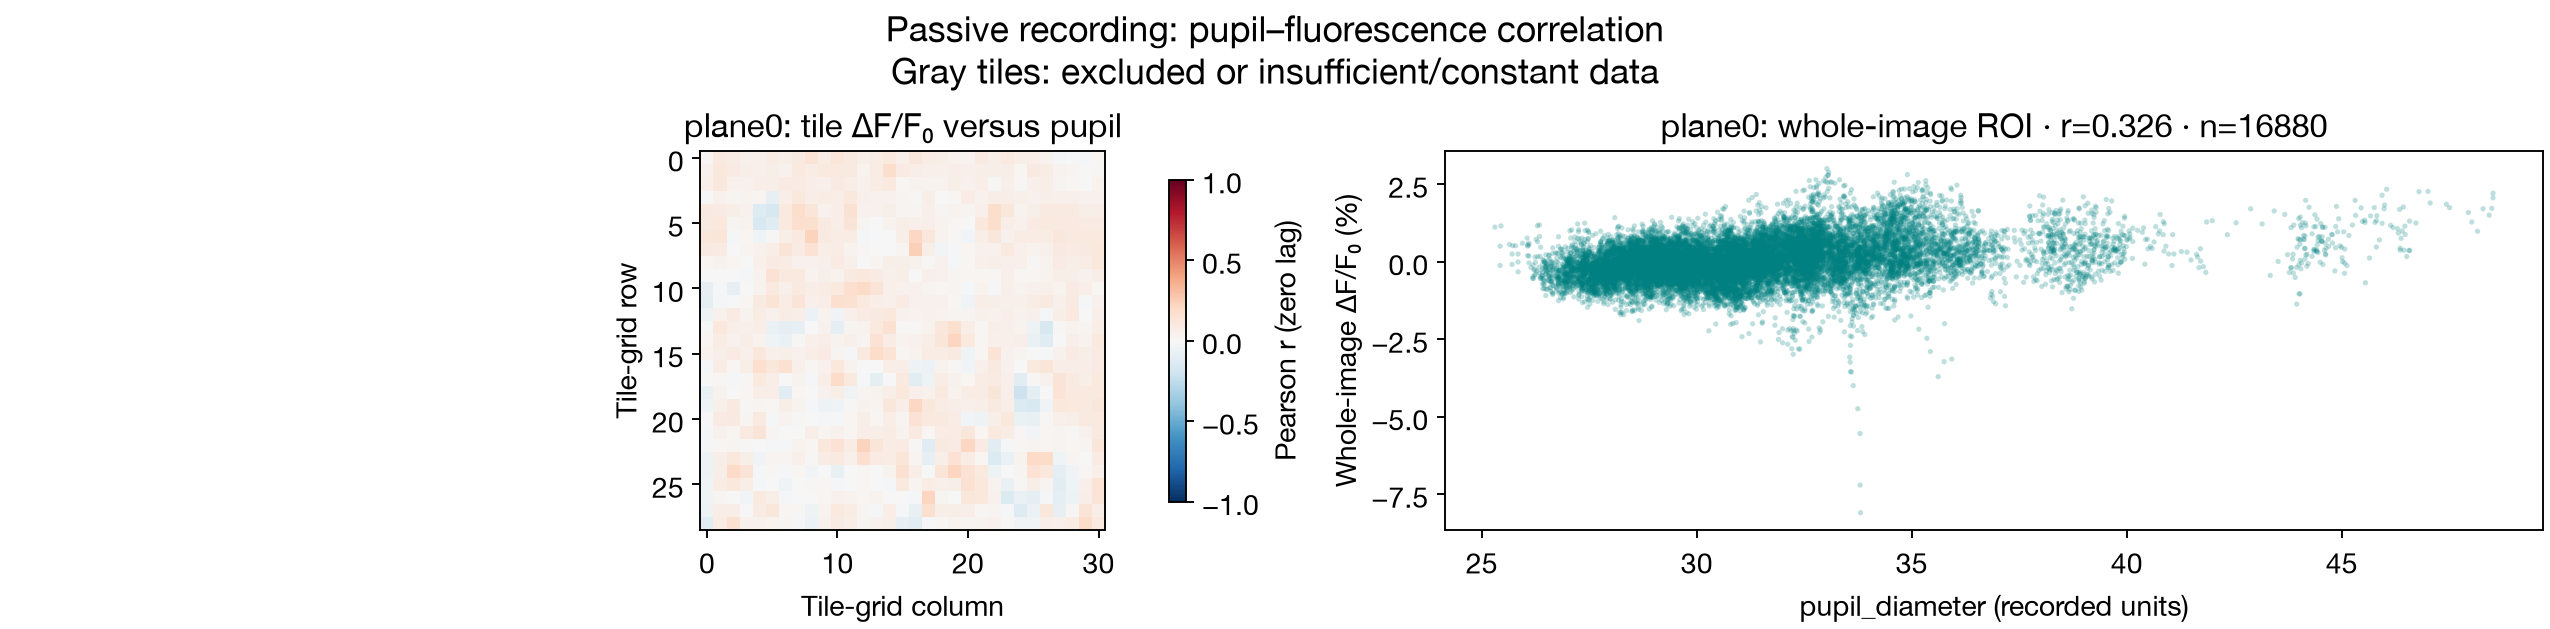

In [ ]:
from pathlib import Path
import runpy
from IPython.display import Image, display
PUPIL_CORRELATION_ROOT = Path('/Users/megyoung/mini2p-preprocessing/results/passive2/suite2p')
PUPIL_TABLE_PATH = ALIGNED_TABLE_PATH
PUPIL_COLUMN = 'pupil_diameter'
PUPIL_MIN_PAIRED_FRAMES = 30
pupil_helpers = runpy.run_path('/Users/megyoung/mini2p-preprocessing/scripts/plot_pupil_dff_correlations.py')
pupil_figure = pupil_helpers['plot_pupil_correlations'](
    PUPIL_CORRELATION_ROOT, PUPIL_TABLE_PATH, PUPIL_COLUMN, PUPIL_MIN_PAIRED_FRAMES)
display(Image(filename=str(pupil_figure)))


## Distribution of tile–pupil correlations

Histograms show finite Pearson r values for retained tiles in each plane, using common bins and axes. The dashed orange line marks each plane’s median. These are distributions across tiles, not independent animal replicates.


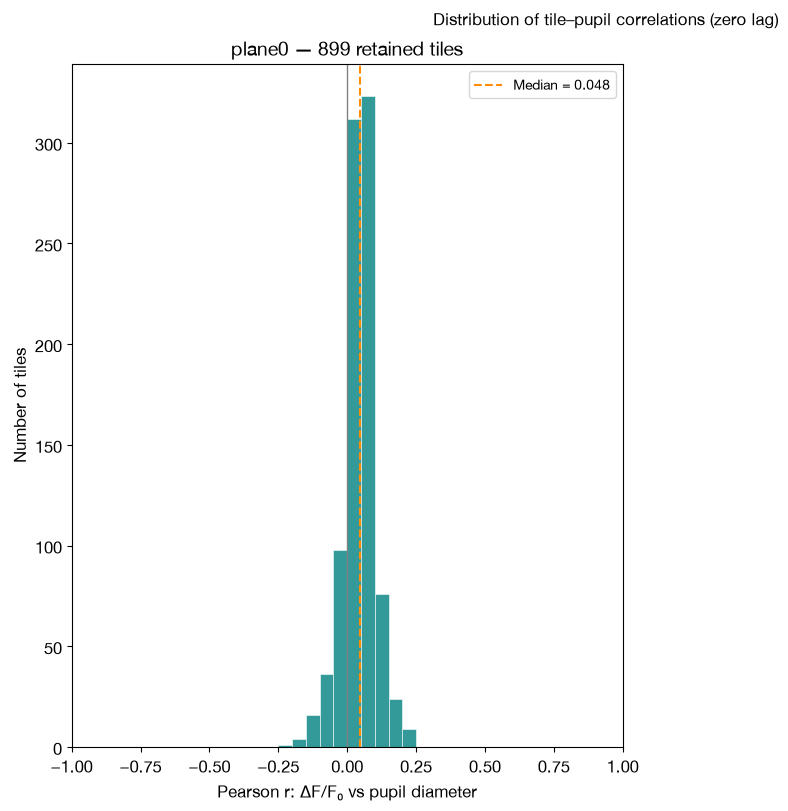

Saved: /Users/megyoung/mini2p-preprocessing/results/passive2/suite2p/pupil_correlation/tile_pupil_correlation_distribution.png


In [ ]:
# Distribution of retained-tile Pearson r values from the pupil correlation cell.
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PUPIL_DISTRIBUTION_DIR = Path('/Users/megyoung/mini2p-preprocessing/results/passive2/suite2p/pupil_correlation')
correlation_table = pd.read_csv(PUPIL_DISTRIBUTION_DIR / 'tile_pupil_correlations.csv')
planes = sorted(correlation_table['plane'].unique())
CORRELATION_BINS = np.linspace(-1, 1, 41)  # same 0.05-wide bins for every plane
fig, axes = plt.subplots(int(np.ceil(len(planes)/2)), 2, figsize=(12, 8),
                         sharex=True, sharey=True, constrained_layout=True, squeeze=False)
for ax, plane in zip(axes.flat, planes):
    values = correlation_table.loc[correlation_table.plane == plane, 'pearson_r'].to_numpy()
    values = values[np.isfinite(values)]
    if not len(values):
        ax.set_title(f'{plane}: no valid correlations')
        continue
    median = float(np.median(values))
    ax.hist(values, bins=CORRELATION_BINS, color='teal', alpha=.8,
            edgecolor='white', linewidth=.5)
    ax.axvline(0, color='gray', linewidth=1)
    ax.axvline(median, color='darkorange', linestyle='--', linewidth=1.5,
               label=f'Median = {median:.3f}')
    ax.set(title=f'{plane} — {len(values)} retained tiles', xlabel='Pearson r: ΔF/F₀ vs pupil diameter',
           ylabel='Number of tiles', xlim=(-1, 1))
    ax.legend()
for ax in list(axes.flat)[len(planes):]:
    ax.set_visible(False)
fig.suptitle('Distribution of tile–pupil correlations (zero lag)')
pupil_distribution_path = PUPIL_DISTRIBUTION_DIR / 'tile_pupil_correlation_distribution.png'
fig.savefig(pupil_distribution_path, dpi=180)
plt.show()
plt.close(fig)
print('Saved:', pupil_distribution_path)


## Pupil correlation: exploratory significance test

Tests zero-lag correlations against all nonzero circular shifts of the pupil trace, preserving its temporal structure and missing-value pattern. Uses two-sided absolute correlations and Benjamini–Hochberg correction across all retained tiles in all detected planes. The primary test includes near-zero shifts; a separately labeled sensitivity analysis excludes shifts within 30 seconds of zero. Results depend on row alignment and the appropriateness of the circular-shift null (including stationarity/wraparound). Shared stimulus, reward, movement, and drift are not controlled; this is within-recording association, not independent evidence across animals.


In [ ]:
from pathlib import Path
import runpy
significance_helpers = runpy.run_path('/Users/megyoung/mini2p-preprocessing/scripts/test_pupil_correlations.py')
pupil_significance_summary = significance_helpers['test_pupil_correlations'](
    Path('/Users/megyoung/mini2p-preprocessing/results/passive2/suite2p'),
    ALIGNED_TABLE_PATH,
    alpha=0.05)
display(pupil_significance_summary)


## Event metrics, pupil states, and Gaussian models

Uses the passive2 traces and its aligned_data table. Calculates 10-second prestimulus z scores, 20-second post-event metrics, pupil-state comparisons and blocked-cross-validation models. Settings and overlap diagnostics are calculated for this recording; no conclusions from the earlier recording are carried over.


In [ ]:
from pathlib import Path
import sys
from IPython.display import Image, display
ANALYSIS_SCRIPT_DIR = Path('/Users/megyoung/mini2p-preprocessing/scripts')
if str(ANALYSIS_SCRIPT_DIR) not in sys.path:
    sys.path.insert(0, str(ANALYSIS_SCRIPT_DIR))
import importlib
import analyze_passive_pupil_events
importlib.reload(analyze_passive_pupil_events)
PASSIVE_ANALYSIS_ROOT = Path('/Users/megyoung/mini2p-preprocessing/results/passive2/suite2p')
PASSIVE_ANALYSIS_TABLE = ALIGNED_TABLE_PATH
ANALYSIS_PRE_S = 10.0
ANALYSIS_POST_S = 20.0
ANALYSIS_MIN_VALID_FRACTION = 0.8
PUPIL_STATE_QUANTILE = 0.5
EVENT_MODEL_BINS_S = (0, 2, 5, 10, 20)
INCLUDE_SPEED_CONTROL = True
MODEL_CV_FOLDS = 5
MODEL_CV_GAP_S = 60.0
analysis_output = analyze_passive_pupil_events.analyze(
    PASSIVE_ANALYSIS_ROOT, PASSIVE_ANALYSIS_TABLE,
    pre_s=ANALYSIS_PRE_S, post_s=ANALYSIS_POST_S,
    min_valid_fraction=ANALYSIS_MIN_VALID_FRACTION,
    pupil_split_quantile=PUPIL_STATE_QUANTILE,
    include_speed=INCLUDE_SPEED_CONTROL, bins=EVENT_MODEL_BINS_S,
    cv_folds=MODEL_CV_FOLDS, cv_gap_s=MODEL_CV_GAP_S)
for filename in ['event_raw_and_z_heatmaps.png', 'pupil_event_responses.png', 'glm_spatial_maps.png']:
    display(Image(filename=str(analysis_output / filename)))


### Pupil diameter and pupil derivative lag correlations
Recreates the comparison in the example, separately for each plane. Lines are mean Pearson correlations across retained tiles; shading is the tile interquartile range, **not animal-level SEM**. Positive lag means fluorescence follows pupil. The pupil and derivative use a configurable 0.5-second Savitzky–Golay window within continuous valid segments. Saved ΔF/F is not additionally smoothed. The image alone does not specify the original smoothing or shading method.

In [ ]:
from pathlib import Path
import sys, importlib
from IPython.display import display, Image

SCRIPT_DIR = HELPER_DIR
sys.path.insert(0, str(SCRIPT_DIR.resolve()))
import plot_pupil_lag_correlations as pupil_lags
importlib.reload(pupil_lags)
LAG_ROOT = SCRIPT_DIR.parent / "results/passive2/suite2p"
LAG_TABLE = ALIGNED_TABLE_PATH
MAX_LAG_S = 3
PUPIL_SMOOTHING_S = 0.5  # Set 0 for no smoothing and central-difference derivative
lag_plot = pupil_lags.plot_lags(LAG_ROOT, LAG_TABLE, max_lag_s=MAX_LAG_S, smoothing_s=PUPIL_SMOOTHING_S)
display(Image(filename=str(lag_plot)))

### Lag curves for significantly positively pupil-correlated tiles
Uses the existing **two-sided circular-shift test**, selecting raw zero-lag pupil correlation > 0 and pooled BH q ≤ 0.05. The same selected tiles are used for diameter and derivative curves. Shading is the tile interquartile range. Selection and plotting use the same recording, so these curves are descriptive and are not independent confirmation of the association.

In [ ]:
# Run the lag-plot cell above and the pupil-significance cell first.
importlib.reload(pupil_lags)
POSITIVE_PUPIL_FDR_ALPHA = 0.05
positive_lag_plot = pupil_lags.plot_lags(
    LAG_ROOT, LAG_TABLE, max_lag_s=MAX_LAG_S,
    smoothing_s=PUPIL_SMOOTHING_S, positive_significant_only=True,
    fdr_alpha=POSITIVE_PUPIL_FDR_ALPHA,
)
display(Image(filename=str(positive_lag_plot)))

### Pupil correlation heatmaps with significant tiles outlined
Black outlines mark either positive or negative correlations passing the existing two-sided circular-shift test with pooled BH q ≤ 0.05. The shared blue–red scale shows raw zero-lag Pearson r. Excluded tiles remain gray.

In [ ]:
from pathlib import Path
import sys, importlib
from IPython.display import Image, display
MAP_SCRIPT_DIR = HELPER_DIR
sys.path.insert(0, str(MAP_SCRIPT_DIR.resolve()))
import plot_significant_pupil_maps as pupil_maps
importlib.reload(pupil_maps)
PUPIL_MAP_FDR_ALPHA = 0.05
outlined_map = pupil_maps.plot_maps(MAP_SCRIPT_DIR.parent / "results/passive2/suite2p", alpha=PUPIL_MAP_FDR_ALPHA)
display(Image(filename=str(outlined_map)))

### Per-tile pupil lag search: 0–16 seconds
Tests every imaging-frame lag using raw pupil diameter and all retained tiles. Positive lag means fluorescence follows pupil. Selects the largest absolute correlation per tile and repeats the full lag search at every circular pupil shift to correct for selecting a peak. BH correction then covers all tiles across planes. Black outlines indicate q ≤ 0.05; lag maps/histograms show only significant tiles. CSV also saves separate maximum-positive-direction and minimum-negative-direction correlations and lags, without separate significance claims. Peak latency is descriptive, not causal; a stimulus-response latency is not necessarily a pupil lag.

In [ ]:
from pathlib import Path
import sys, importlib
from IPython.display import Image, display
LAG_SEARCH_SCRIPTS = HELPER_DIR
sys.path.insert(0, str(LAG_SEARCH_SCRIPTS.resolve()))
import test_pupil_lag_range as lag_search
importlib.reload(lag_search)
SEARCH_MAX_LAG_S = 16
SEARCH_FDR_ALPHA = 0.05
lag_search_plot = lag_search.scan(LAG_SEARCH_SCRIPTS.parent / "results/passive2/suite2p",
    ALIGNED_TABLE_PATH,
    max_lag_s=SEARCH_MAX_LAG_S, alpha=SEARCH_FDR_ALPHA)
display(Image(filename=str(lag_search_plot)))

### Distribution of positive dominant peak lags
Includes tiles whose strongest absolute pupil correlation over 0–16 s is positive (`peak_r > 0`). This is a descriptive selection, not significant tiles. All-plane pooling counts tiles, not independent animals.

In [ ]:
from pathlib import Path
import sys, importlib
from IPython.display import display, Image
PEAK_SCRIPTS = HELPER_DIR
sys.path.insert(0, str(PEAK_SCRIPTS.resolve()))
import plot_positive_peak_lags as positive_peaks
importlib.reload(positive_peaks)
display(Image(filename=str(positive_peaks.plot_distribution(PEAK_SCRIPTS.parent / "results/passive2/suite2p"))))

### Event responses sorted by pupil-size correlation
Uses the same retained tiles and matched trial baseline comparison, ordered within each plane by descending full-recording zero-lag Pearson correlation with raw pupil diameter. The order is identical across events and baseline versions. Y ticks show original tile ID and correlation; no significance filtering.

In [ ]:
from pathlib import Path
import sys, importlib
from IPython.display import Image, display
SORT_SCRIPTS = HELPER_DIR
sys.path.insert(0, str(SORT_SCRIPTS.resolve()))
import plot_pupil_sorted_events as sorted_events
importlib.reload(sorted_events)
sorted_plot = sorted_events.plot_sorted(SORT_SCRIPTS.parent / "results/passive2/suite2p",
    ALIGNED_TABLE_PATH,
    color_limit_percent=EVENT_COLOR_LIMIT_PERCENT, color_percentile=EVENT_COLOR_PERCENTILE)
display(Image(filename=str(sorted_plot)))

### Event response comparison sorted by pupil correlation
Uses all retained tiles, sorted within each plane by freshly calculated zero-lag Pearson correlation with raw pupil diameter (most positive at top; missing correlations last). The same ordering is used for all events and both baseline displays. Sorting is descriptive and does not filter for significance.

In [ ]:
from pathlib import Path
import sys, importlib
from IPython.display import Image, display
SORT_SCRIPTS = HELPER_DIR
sys.path.insert(0,str(SORT_SCRIPTS.resolve()))
import plot_passive_event_aligned_tiles as sorted_events
importlib.reload(sorted_events)
sorted_event_plot = sorted_events.plot_prestimulus_comparison(
    SORT_SCRIPTS.parent / "results/passive2/suite2p",
    pupil_table_path=ALIGNED_TABLE_PATH,
    color_limit_percent=EVENT_COLOR_LIMIT_PERCENT, color_percentile=EVENT_COLOR_PERCENTILE)
display(Image(filename=str(sorted_event_plot)))

### Pupil diameter aligned to grating and reward events
Uses the same window as the saved tile heatmaps. Black = trial mean; faint lines = individual trials; shading = SEM across available trials within this recording, not across animals. Raw pupil diameter is plotted once, since all planes share the pupil measurement.

In [ ]:
from pathlib import Path
import sys, importlib
from IPython.display import display, Image
PUPIL_EVENT_SCRIPTS = HELPER_DIR
sys.path.insert(0,str(PUPIL_EVENT_SCRIPTS.resolve()))
import plot_event_aligned_pupil as pupil_event_plot
importlib.reload(pupil_event_plot)
pupil_event_path = pupil_event_plot.plot_pupil(PUPIL_EVENT_SCRIPTS.parent / "results/passive2/suite2p",
    ALIGNED_TABLE_PATH)
display(Image(filename=str(pupil_event_path)))

### Whole-image NE fluorescence tuning by pupil size
Bins simultaneous pupil diameter into shared equal-width bins and averages saved whole-image ROI ΔF/F per plane. Shading is sample-based SEM (sample SD / sqrt(valid paired frame count)). Consecutive frames are correlated, so this can understate uncertainty and is not animal-level SEM. Occupancy bars show sample counts; sparse bins are omitted. Parameters below control bin count and minimum paired samples.

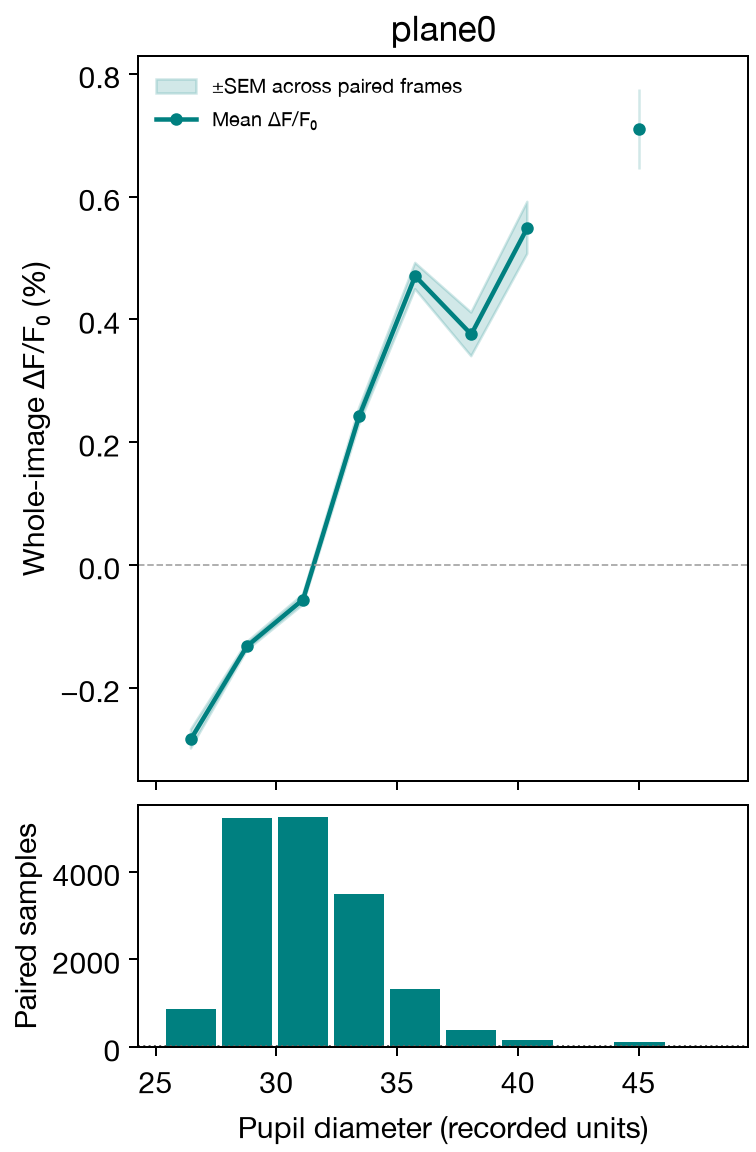

In [ ]:
from pathlib import Path
import sys, importlib
from IPython.display import display, Image
TUNING_SCRIPTS = HELPER_DIR
sys.path.insert(0,str(TUNING_SCRIPTS.resolve()))
import plot_pupil_ne_tuning as pupil_tuning
importlib.reload(pupil_tuning)
PUPIL_N_BINS = 10
PUPIL_BIN_MIN_SAMPLES = 30
tuning_path = pupil_tuning.plot_tuning(TUNING_SCRIPTS.parent / "results/passive2/suite2p",
    ALIGNED_TABLE_PATH,
    n_bins=PUPIL_N_BINS, min_samples=PUPIL_BIN_MIN_SAMPLES)
display(Image(filename=str(tuning_path)))

### Pupil tuning averaged across all planes
Averages whole-image ΔF/F equally across planes at each time point, then bins this mean trace by pupil diameter. Requires valid values in every plane. Shading is SEM across time samples within each bin, not across planes or animals; temporal autocorrelation may understate uncertainty. Run the per-plane tuning cell first.

In [ ]:
importlib.reload(pupil_tuning)
all_planes_tuning_path = pupil_tuning.plot_plane_average(TUNING_SCRIPTS.parent / "results/passive2/suite2p")
display(Image(filename=str(all_planes_tuning_path)))

### Passive2 plane 0: cropped, high-contrast, fast video
Rows 7–11 and columns 10–14 are inclusive zero-based coordinates relative to the valid Suite2p crop, with 32-pixel tiles. Fixed 10th–98th percentile intensity contrast, 20-frame rolling average, full recording (shorter averaging windows at the recording boundaries), 10× playback. Registered intensity, not ΔF/F. Existing videos are preserved.

In [ ]:
from pathlib import Path
import sys, importlib
from IPython.display import Video, display
CROP_SCRIPT_DIR = HELPER_DIR
sys.path.insert(0,str(CROP_SCRIPT_DIR.resolve()))
import export_nlight_crop_video as crop_video
importlib.reload(crop_video)
cropped_video = crop_video.export_crop(CROP_SCRIPT_DIR.parent / "results/passive2/suite2p",
    start_min=0, stop_min=None, rows=(7,11), columns=(10,14), tile_size=32,
    speed=10, window=20, contrast=(10,98))
display(Video(str(cropped_video), embed=False))

### Passive2 plane 0: full-field video styled after the reference
Full valid field, grayscale on black, no grid, fixed contrast, 40-frame averaging (~1.33 s), 10× playback. No scale bar without verified spatial calibration.

In [ ]:
from pathlib import Path
import sys, importlib
from IPython.display import Video, display
REFERENCE_SCRIPTS = HELPER_DIR
sys.path.insert(0,str(REFERENCE_SCRIPTS.resolve()))
import export_nlight_reference_video as reference_video
importlib.reload(reference_video)
reference_path = reference_video.export_reference_style(REFERENCE_SCRIPTS.parent/"results/passive2/suite2p", window=40, speed=10, contrast=(10,99.8), recording_label="passive2")
display(Video(str(reference_path), embed=False))

### Reference-style passive video, 2× zoom
Centered crop with half the width and height, displayed at the same output size. Full recording, 40-frame averaging, 10× playback.

In [ ]:
importlib.reload(reference_video)
zoomed_reference_path = reference_video.export_reference_style(REFERENCE_SCRIPTS.parent/"results/passive2/suite2p", window=40, speed=10, contrast=(10,99.8), zoom=2, recording_label="passive2")
display(Video(str(zoomed_reference_path), embed=False))

### Passive video smoothing comparison: 4 and 8 frames
Full field and 2× zoom, using the softened-highlight 40-frame reference contrast limits and unchanged 10× playback.

In [ ]:
from pathlib import Path
import sys, json, importlib
from IPython.display import Video, display
PASSIVE_COMPARE_SCRIPTS = HELPER_DIR
sys.path.insert(0,str(PASSIVE_COMPARE_SCRIPTS.resolve()))
import export_nlight_reference_video as reference_video
importlib.reload(reference_video)
PASSIVE_COMPARE_ROOT = PASSIVE_COMPARE_SCRIPTS.parent/"results/passive2/suite2p"
passive_contrast_references = {}
for zoom in (1, 2):
    candidates = sorted((PASSIVE_COMPARE_ROOT/'videos').glob(f'passive2_plane0_reference_zoom{zoom}x_avg40_10x*.json'), key=lambda p: p.stat().st_mtime)
    if not candidates:
        raise FileNotFoundError(f'Run the passive2 {zoom}x 40-frame video cell first')
    passive_contrast_references[zoom] = candidates[-1].name
for zoom, reference_name in passive_contrast_references.items():
    settings = json.loads((PASSIVE_COMPARE_ROOT/"videos"/reference_name).read_text())
    for avg_frames in (4,8):
        path = reference_video.export_reference_style(PASSIVE_COMPARE_ROOT, window=avg_frames, speed=10,
            zoom=zoom, recording_label="passive2", contrast=(10,99.8), contrast_limits=settings["contrast_limits"])
        display(Video(str(path), embed=False))

### Passive2: 3× centered zoom
4- and 8-frame averaging, 10× playback. Uses the same fixed contrast limits as the softened 2× zoom for direct comparison.

In [ ]:
# Run the passive smoothing-comparison setup above first.
importlib.reload(reference_video)
zoom3_settings = json.loads((PASSIVE_COMPARE_ROOT/"videos"/passive_contrast_references[2]).read_text())
for avg_frames in (4,8):
    zoom3_path = reference_video.export_reference_style(PASSIVE_COMPARE_ROOT, window=avg_frames, speed=10,
        zoom=3, recording_label="passive2", contrast=(10,99.8), contrast_limits=zoom3_settings["contrast_limits"])
    display(Video(str(zoom3_path), embed=False))

### Passive2: 3× zoom with 20-frame averaging
Full recording, ~0.67-second rolling average, 10× playback, same fixed contrast as the other 3× versions.

In [ ]:
# Run the passive smoothing-comparison setup above first.
importlib.reload(reference_video)
zoom3_20_settings = json.loads((PASSIVE_COMPARE_ROOT/"videos"/passive_contrast_references[2]).read_text())
zoom3_20_path = reference_video.export_reference_style(PASSIVE_COMPARE_ROOT, window=20, speed=10,
    zoom=3, recording_label="passive2", contrast=(10,99.8), contrast_limits=zoom3_20_settings["contrast_limits"])
display(Video(str(zoom3_20_path), embed=False))